# Motif-motif interaction

In [1]:
import pandas as pd
import os
import glob
import numpy as np

## Preprocessing-Integration

In [12]:
import os
import glob
import pandas as pd

# --- 1. Set file path ---
directory_path = './tf/tf_tf/'

# Check if the directory exists
if not os.path.isdir(directory_path):
    print(f"Error: Directory '{directory_path}' does not exist. Please check the path.")
else:
    # --- 2. Find all .csv files ---
    csv_files = glob.glob(os.path.join(directory_path, '*.csv'))
    
    if not csv_files:
        print(f"Warning: No .csv files found in directory '{directory_path}'.")
    else:
        print(f"Found {len(csv_files)} .csv files, starting processing...")
        
        # --- 3. Prepare a list to store each processed DataFrame ---
        all_dataframes = []

        # --- 4. Iterate through and process each file ---
        for file_path in csv_files:
            try:
                # a. Extract the filename to serve as the final row index
                file_name_as_index = os.path.basename(file_path).removesuffix('.csv')
                
                # b. Read the CSV file
                # Use index_col=0 to treat the first column of the CSV as the initial index
                # This correctly reads your single-row data
                single_row_df = pd.read_csv(file_path, index_col=0)
                
                # c. Rename the row index to the filename
                # The row name might be '0' after reading; we replace it here
                single_row_df.index = [file_name_as_index]
                
                # d. Append the processed single-row DataFrame to the list
                all_dataframes.append(single_row_df)
                
                print(f"  - Processed: {os.path.basename(file_path)}")

            except Exception as e:
                print(f"  - Error occurred while processing file '{file_path}': {e}")

        # --- 5. Concatenate all DataFrames row-wise ---
        if all_dataframes:
            # pd.concat automatically takes the union of all columns (join='outer')
            # It aligns column names automatically; missing values are filled with NaN
            final_df = pd.concat(all_dataframes)
            
            # (Optional) Replace NaN values with 0
            final_df = final_df.fillna(0)
            
            # --- 6. Display and save results ---
            print("\n--- Merge Complete ---")
            print("Final generated DataFrame (first 5 rows):")
            print(final_df.head())
            
            # Save to a new CSV file
            output_path = 'tf_tf_combined.csv'
            final_df.to_csv(output_path)
            print(f"\nResults saved to: {output_path}")
        else:
            print("\nNo files were successfully processed; cannot generate final result.")

找到了 14 个 .csv 文件，开始处理...
  - 已处理: b_cells.csv
  - 已处理: b-cell_lineage.csv
  - 已处理: cycling_cells.csv
  - 已处理: dc.csv
  - 已处理: early_mk.csv
  - 已处理: erythroid.csv
  - 已处理: hsc_mpp.csv
  - 已处理: ilc.csv
  - 已处理: macrophages.csv
  - 已处理: mast_cells.csv
  - 已处理: monocytes.csv
  - 已处理: pdc.csv
  - 已处理: plasma_cells.csv
  - 已处理: t_cells.csv

--- 合并完成 ---
最终生成的DataFrame (前5行):
                AHR->NR/3  AHR->ZNF384/1  AIRE->CREB/ATF/1  AIRE->CUX/2  \
b_cells          0.535150      -0.119704         -0.018066     0.007552   
b-cell_lineage  -0.051192       0.000000          0.000000     0.000000   
cycling_cells   -0.148300       0.000000          0.000000     0.000000   
dc               0.000000       0.000000          0.000000     0.000000   
early_mk         0.681072       0.000000         -0.009846     0.000000   

                AIRE->Ebox/CACGTG/1  AIRE->Ebox/CACGTG/2  AIRE->FOX/2  \
b_cells                    0.010484            -0.024072     0.016337   
b-cell_lineage             0.00

## Filter: remove Accessibility, take absolute value, merge bidirectional edges

In [79]:
data = pd.read_csv('./tf/tf_tf/tf_tf_combined.csv', index_col=0)
data

,AHR->NR/3,AHR->ZNF384/1,AIRE->CREB/ATF/1,AIRE->CUX/2,AIRE->Ebox/CACGTG/1,AIRE->Ebox/CACGTG/2,AIRE->FOX/2,AIRE->FOX/6,AIRE->GFI,AIRE->HAND1,...,ZNF549->HD/10,ZNF549->NR/2,ZNF563->CREB3/XBP1,ZNF680->HD/13,ZNF768->E2F/3,ZNF768->GMEB2/3,ZNF768->P53-like/3,ZNF768->ZNF140,ZNF768->ZNF85,ZSCAN3->ZNF384/1
b_cells,0.535150,-0.119704,-0.018066,0.007552,0.010484,-0.024072,0.016337,0.029250,0.028171,-0.024173,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
b-cell_lineage,-0.051192,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
cycling_cells,-0.148300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.113673,0.068921,-0.033386,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
dc,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.046325,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
early_mk,0.681072,0.000000,-0.009846,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
erythroid,0.526616,-0.120353,-0.005197,0.035781,0.011579,-0.030220,0.042167,0.051015,0.028579,-0.036199,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
hsc_mpp,0.522776,-0.112938,-0.010096,0.014823,0.000000,-0.057144,0.019682,0.019275,0.016941,-0.022239,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ilc,0.521030,-0.107911,-0.017008,0.013979,0.009788,-0.084154,0.000000,0.025299,0.019454,-0.032379,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
macrophages,-0.201426,0.000000,-0.026399,0.000000,0.092372,-0.012909,0.000000,0.028431,0.095824,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
mast_cells,0.237101,0.000000,-0.024225,0.000000,0.000000,-0.025784,0.000000,0.014985,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [80]:
# 1. 找到所有列名中包含 'Accessibility' 的列
cols_to_drop = [col for col in data.columns if 'Accessibility' in col]
# 或者使用更Pandas化的方式:
# cols_to_drop = data.columns[data.columns.str.contains('Accessibility')]

print("将要被删除的列:")
print(cols_to_drop)

# 2. 使用 .drop() 函数删除这些列
#    axis=1 表示我们要删除的是列
data_cleaned = data.drop(columns=cols_to_drop)

print("\n清理后的 DataFrame:")
print(data_cleaned)

将要被删除的列:
['Accessibility->AP1/1', 'Accessibility->AP1/2', 'Accessibility->BATF', 'Accessibility->CCAAT/CEBP', 'Accessibility->CPEB1', 'Accessibility->CTCF', 'Accessibility->CUX/2', 'Accessibility->DDIT3+CEBPA', 'Accessibility->DMRT1', 'Accessibility->DMRT3', 'Accessibility->E2F/2', 'Accessibility->EBF1', 'Accessibility->EGR', 'Accessibility->ETS/1', 'Accessibility->ETS/2', 'Accessibility->Ebox/CACGTG/1', 'Accessibility->Ebox/CACGTG/2', 'Accessibility->Ebox/CAGCTG', 'Accessibility->FOX/1', 'Accessibility->FOX/2', 'Accessibility->FOX/3', 'Accessibility->FOX/6', 'Accessibility->FOX/7', 'Accessibility->FOX/9', 'Accessibility->GATA', 'Accessibility->GC-tract', 'Accessibility->GCM', 'Accessibility->GFI', 'Accessibility->GLI', 'Accessibility->GLIS', 'Accessibility->GMEB2/3', 'Accessibility->GRHL', 'Accessibility->HAND1', 'Accessibility->HD/1', 'Accessibility->HD/14', 'Accessibility->HD/15', 'Accessibility->HD/16', 'Accessibility->HD/17', 'Accessibility->HD/18', 'Accessibility->HD/19', 'Access

In [82]:
data_positive_abs = data_cleaned.abs()

In [83]:
data_positive_abs

,AHR->NR/3,AHR->ZNF384/1,AIRE->CREB/ATF/1,AIRE->CUX/2,AIRE->Ebox/CACGTG/1,AIRE->Ebox/CACGTG/2,AIRE->FOX/2,AIRE->FOX/6,AIRE->GFI,AIRE->HAND1,...,ZNF549->HD/10,ZNF549->NR/2,ZNF563->CREB3/XBP1,ZNF680->HD/13,ZNF768->E2F/3,ZNF768->GMEB2/3,ZNF768->P53-like/3,ZNF768->ZNF140,ZNF768->ZNF85,ZSCAN3->ZNF384/1
b_cells,0.535150,0.119704,0.018066,0.007552,0.010484,0.024072,0.016337,0.029250,0.028171,0.024173,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
b-cell_lineage,0.051192,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
cycling_cells,0.148300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.113673,0.068921,0.033386,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
dc,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.046325,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
early_mk,0.681072,0.000000,0.009846,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
erythroid,0.526616,0.120353,0.005197,0.035781,0.011579,0.030220,0.042167,0.051015,0.028579,0.036199,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
hsc_mpp,0.522776,0.112938,0.010096,0.014823,0.000000,0.057144,0.019682,0.019275,0.016941,0.022239,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ilc,0.521030,0.107911,0.017008,0.013979,0.009788,0.084154,0.000000,0.025299,0.019454,0.032379,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
macrophages,0.201426,0.000000,0.026399,0.000000,0.092372,0.012909,0.000000,0.028431,0.095824,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
mast_cells,0.237101,0.000000,0.024225,0.000000,0.000000,0.025784,0.000000,0.014985,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [84]:
# 1. 准备工作：获取所有列名并创建一个快速查找的集合
all_columns = data_positive_abs.columns
column_set = set(all_columns)

# 2. 准备一个集合，用于存放已经找到的“范式化”配对，以避免重复计数
found_pairs = set()
# 准备一个列表，用于存放具体的配对列名，方便查看
reversed_columns_list = []

# 3. 遍历所有列名
for col_name in all_columns:
    # 尝试按 "->" 分割列名
    parts = col_name.split('->')
    
    # 确保列名格式正确（恰好被 '->' 分为两部分）
    if len(parts) == 2:
        part1, part2 = parts[0], parts[1]
        
        # 创建反向的列名
        reverse_name = f"{part2}->{part1}"
        
        # 创建一个“范式化”的键（使用 frozenset，与顺序无关）
        # frozenset({'A', 'B'}) 和 frozenset({'B', 'A'}) 是等价的
        canonical_pair = frozenset((part1, part2))
        
        # 核心逻辑：
        # 1. 检查反向名称是否存在
        # 2. 检查这个范式化的配对是否已经被记录过（防止重复计数）
        if reverse_name in column_set and canonical_pair not in found_pairs:
            # 如果都满足，说明我们找到了一个新的配对
            found_pairs.add(canonical_pair)
            reversed_columns_list.append((col_name, reverse_name))

# 4. 报告结果
count = len(found_pairs)

print(f"检查完毕！\n在 {len(all_columns)} 个总列名中，共找到 {count} 对前后顺序颠倒的列名。")

if count > 0:
    print("\n具体配对如下:")
    # 为了方便查看，我们只打印前10对
    for i, pair in enumerate(reversed_columns_list[:10]):
        print(f"  {i+1}: {pair[0]} <---> {pair[1]}")
    if count > 10:
        print(f"  ... (还有 {count - 10} 对未显示)")

检查完毕！
在 47605 个总列名中，共找到 16613 对前后顺序颠倒的列名。

具体配对如下:
  1: AHR->NR/3 <---> NR/3->AHR
  2: AIRE->CREB/ATF/1 <---> CREB/ATF/1->AIRE
  3: AIRE->CUX/2 <---> CUX/2->AIRE
  4: AIRE->Ebox/CACGTG/1 <---> Ebox/CACGTG/1->AIRE
  5: AIRE->Ebox/CACGTG/2 <---> Ebox/CACGTG/2->AIRE
  6: AIRE->FOX/6 <---> FOX/6->AIRE
  7: AIRE->GFI <---> GFI->AIRE
  8: AIRE->HAND1 <---> HAND1->AIRE
  9: AIRE->HD/1 <---> HD/1->AIRE
  10: AIRE->HD/14 <---> HD/14->AIRE
  ... (还有 16603 对未显示)


In [86]:
# 1. 准备一个列表来存放所有新生成的列 (Pandas Series)
new_columns_list = []
# 准备一个集合，用于存放已经处理过的原始列名
processed_columns = set()

# 2. 遍历所有原始列名
for col_name in data_positive_abs.columns:
    if col_name in processed_columns:
        continue
    
    parts = col_name.split('->')
    if len(parts) != 2:
        # 对于格式不正确的列，可以决定如何处理，这里我们直接保留
        new_columns_list.append(data_positive_abs[col_name])
        continue
        
    part1, part2 = parts[0], parts[1]
    reverse_name = f"{part2}->{part1}"
    canonical_name = "_".join(sorted((part1, part2)))
    
    # 3. 检查反向列是否存在
    if reverse_name in data_positive_abs.columns:
        # --- 情况一：存在双向边 ---
        # a. 计算新列的数据
        new_col_data = data_positive_abs[col_name] + data_positive_abs[reverse_name]
        # b. 将新列的名称设置为范式化名称
        new_col_data.name = canonical_name
        
        # c. 将计算出的新列(Series)添加到列表中
        new_columns_list.append(new_col_data)
        
        # d. 将原始的两列都标记为已处理
        processed_columns.add(col_name)
        processed_columns.add(reverse_name)
    else:
        # --- 情况二：只存在单向边 ---
        # a. 复制单向边的数据
        new_col_data = data_positive_abs[col_name]
        # b. 将新列的名称设置为范式化名称
        new_col_data.name = canonical_name
        
        # c. 将新列(Series)添加到列表中
        new_columns_list.append(new_col_data)
        
        # d. 将该列标记为已处理
        processed_columns.add(col_name)

# 4. 在循环结束后，使用 pd.concat 一次性高效地将所有列合并成最终的DataFrame
#    axis=1 表示按列进行合并
undirected_df = pd.concat(new_columns_list, axis=1)

# 5. (可选) 对最终的列名进行排序
undirected_df = undirected_df.reindex(sorted(undirected_df.columns), axis=1)

print("优化后，高效生成的无向 DataFrame:")
print(undirected_df)

优化后，高效生成的无向 DataFrame:
                AHR_AIRE  AHR_AP1/1  AHR_AP1/2  AHR_BATF  AHR_CCAAT/CEBP  \
b_cells         0.000000   0.000000   0.000000  0.000000        0.000000   
b-cell_lineage  0.000000   0.000000   0.000000  0.000000        0.000000   
cycling_cells   0.021338   0.005167   0.000000  0.003602        0.007763   
dc              0.000000   0.000000   0.000000  0.000000        0.000000   
early_mk        0.000000   0.000000   0.003806  0.000000        0.000000   
erythroid       0.000000   0.000000   0.012514  0.000000        0.005253   
hsc_mpp         0.000000   0.000000   0.006046  0.000000        0.000000   
ilc             0.000000   0.000000   0.000000  0.000000        0.002618   
macrophages     0.007469   0.007130   0.000000  0.039761        0.000000   
mast_cells      0.000000   0.147718   0.004861  0.001689        0.000000   
monocytes       0.000000   0.000000   0.000000  0.000000        0.002869   
pdc             0.000000   0.000000   0.044298  0.000000        0

In [90]:
47605-16613

30992

In [122]:
undirected_df.to_csv('./tf/tf_tf/processed.csv')

## Statistically specific and shared

In [123]:
non_zero_counts_per_column = (undirected_df != 0).sum(axis=0)

In [124]:
most_common_interactions = non_zero_counts_per_column.sort_values(ascending=False)
print("\n最普遍的调控关系 (在最多的细胞类型中出现):")
print(most_common_interactions.head())


最普遍的调控关系 (在最多的细胞类型中出现):
PRDM5_ZNF143     14
HAND1_YY1        14
NR/12_TBX/3      14
ZNF554_ZSCAN3    14
MEF2_NR/2        14
dtype: int64


In [127]:
most_common_interactions.to_csv('./tf/tf_tf/all_30992.csv')

In [128]:
meta = pd.DataFrame(most_common_interactions)
meta[0].value_counts()

0
1     7156
2     4603
3     3304
4     2373
5     1839
6     1590
7     1541
14    1489
8     1436
9     1231
10    1168
11    1098
13    1095
12    1069
Name: count, dtype: int64

### specific

In [129]:
# --- 步骤一：统计每种互作在多少细胞类型中出现 ---

# (undirected_df > 0) 会生成一个布尔矩阵
# .sum(axis=0) 会计算每列中 True 的数量
non_zero_counts = (undirected_df > 0).sum(axis=0)

print("每种互作在多少细胞类型中出现:")
print(non_zero_counts)
print("-" * 40)


# --- 步骤二：筛选出只出现一次的互作 ---

specific_interaction_names = non_zero_counts[non_zero_counts == 1].index

print("只在一种细胞类型中出现的互作对:")
print(list(specific_interaction_names))
print("-" * 40)


# --- 步骤三：提取这些特异性互作的详细信息 ---

# 1. 先只保留特异性互作的列
specific_df = undirected_df[specific_interaction_names]

# 2. 使用 .stack() 方法将DataFrame转换为Series，这会移除所有值为0的项（在稀疏格式下）
#    为了确保移除0，我们先将0替换为NaN
stacked_series = specific_df.replace(0, pd.NA).stack()

# 3. 将得到的Series重置索引，转换为我们想要的最终格式
specific_interactions_details = stacked_series.reset_index()

# 4. 重命名列以获得清晰的输出
specific_interactions_details.columns = ['CellType', 'Interaction', 'Strength']


# --- 打印最终结果 ---
print("特异性互作的详细信息:")
if specific_interactions_details.empty:
    print("没有找到任何只在一种细胞类型中出现的互作。")
else:
    print(specific_interactions_details)

每种互作在多少细胞类型中出现:
AHR_AIRE          2
AHR_AP1/1         3
AHR_AP1/2         6
AHR_BATF          3
AHR_CCAAT/CEBP    5
                 ..
ZNF768_ZNF784     1
ZNF768_ZNF85      8
ZNF768_ZSCAN3     2
ZNF85_ZSCAN3      3
ZSCAN3_ZSCAN4     6
Length: 30992, dtype: int64
----------------------------------------
只在一种细胞类型中出现的互作对:
['AHR_CREB/ATF/1', 'AHR_CUX/1', 'AHR_DDIT3+CEBPA', 'AHR_DMRT1', 'AHR_DMRT3', 'AHR_E2F/4', 'AHR_EBF1', 'AHR_ETS/2', 'AHR_FEZF1', 'AHR_FOX/1', 'AHR_FOX/6', 'AHR_FOX/9', 'AHR_GC-tract', 'AHR_GFI', 'AHR_HD/13', 'AHR_HD/18', 'AHR_HD/21', 'AHR_HD/23', 'AHR_HD/25', 'AHR_HD/4', 'AHR_HD/6', 'AHR_HD/8', 'AHR_HD/9', 'AHR_HIC/2', 'AHR_INSM1', 'AHR_IRF/1', 'AHR_IRF/4', 'AHR_KAISO', 'AHR_KLF/SP/3', 'AHR_LIN54', 'AHR_MAF', 'AHR_MECP2', 'AHR_MEF2', 'AHR_MTF1', 'AHR_MYB/2', 'AHR_NFAT/1', 'AHR_NFAT/3', 'AHR_NFAT/4', 'AHR_NFI/1', 'AHR_NFI/2', 'AHR_NR/1', 'AHR_NR/15', 'AHR_NR/16', 'AHR_NR/2', 'AHR_NR/20', 'AHR_OVOL1', 'AHR_P53-like/2', 'AHR_RBPJ', 'AHR_RFX/3', 'AHR_SCRT1', 'AHR_SNAI2', 'AH

In [130]:
specific_interactions_details.to_csv('./tf/tf_tf/specific.csv')

In [118]:
specific_interactions_details['CellType'].value_counts()

CellType
macrophages       1723
b-cell_lineage    1280
cycling_cells     1242
dc                 798
plasma_cells       669
mast_cells         302
early_mk           300
pdc                253
monocytes          119
ilc                108
erythroid           94
hsc_mpp             92
t_cells             90
b_cells             86
Name: count, dtype: int64

In [119]:
strength_series = specific_interactions_details['Strength']

In [ ]:
plt.figure(figsize=(10, 6))

# 使用 Seaborn 绘制 'Strength' 列的分布
sns.histplot(strength_series, kde=True, bins=15, color='purple')

plt.title('Distribution of Interaction Strengths for Specific Pairs')
plt.xlabel('Interaction Strength')
plt.ylabel('Frequency (Count)')
plt.grid(True, linestyle='--', alpha=0.7)

# 保存图像
# plt.savefig('specific_strength_distribution.png')
plt.show()

### common

In [131]:
# --- 步骤一：识别在所有细胞类型中都存在的互作 ---

# 1. 获取细胞类型的总数（即DataFrame的行数）
num_cell_types = len(undirected_df)
print(f"共有 {num_cell_types} 种细胞类型。")

# 2. 统计每种互作在多少细胞类型中出现（即每列的非零值数量）
non_zero_counts = (undirected_df > 0).sum(axis=0)

# 3. 筛选出那些出现次数等于细胞总数的互作
common_interaction_names = non_zero_counts[non_zero_counts == num_cell_types].index

print(f"\n在所有细胞类型中都存在的共有互作是:")
print(list(common_interaction_names))
print("-" * 50)


# --- 步骤二：对这些共有互作的值进行相加 ---

if not common_interaction_names.empty:
    # 1. 从原始DataFrame中只选择这些共有的互作列
    common_df = undirected_df[common_interaction_names]

    # 2. 对筛选出的列按列求和 (axis=0)
    total_strength_of_common = common_df.sum(axis=0)

    # --- 打印最终结果 ---
    print("共有互作在所有细胞中的总交互强度:")
    print(total_strength_of_common)
else:
    print("数据中没有发现在所有细胞类型中都存在的TF互作。")

共有 14 种细胞类型。

在所有细胞类型中都存在的共有互作是:
['AHR_CTCF', 'AHR_Ebox/CAGCTG', 'AHR_HIF', 'AHR_ZIC', 'AP1/1_AP1/2', 'AP1/1_HD/2', 'AP1/1_HD/5', 'AP1/1_IRF/1', 'AP1/1_NR/3', 'AP1/1_TBX/2', 'AP1/2_CREB3/XBP1', 'AP1/2_Ebox/CACGTG/1', 'AP1/2_HAND1', 'AP1/2_MAF', 'AP1/2_NR/16', 'AP1/2_NR/19', 'AP1/2_NR/7', 'AP1/2_PAX/2', 'AP1/2_PLAG1', 'AP1/2_RFX/3', 'AP1/2_SMARCA5', 'AP1/2_TBX/2', 'AP1/2_ZNF134', 'AP1/2_ZNF257', 'AP1/2_ZNF449', 'ARI5A_HD/2', 'BATF_HD/22', 'BATF_IRF/1', 'BATF_ZNF418', 'BCL6/2_ETS/1', 'BCL6/2_Ebox/CAGATGG', 'BCL6/2_HD/2', 'BCL6/2_HIC/1', 'BCL6/2_SMAD', 'BCL6/2_SPZ1', 'BCL6/2_ZFN121', 'BCL6/2_ZNF329', 'CCAAT/CEBP_CREB/ATF/3', 'CCAAT/CEBP_HD/20', 'CCAAT/CEBP_HD/4', 'CCAAT/CEBP_P53-like/3', 'CCAAT/CEBP_ZNF140', 'CPEB1_TFAP2/1', 'CREB/ATF/1_CREB/ATF/2', 'CREB/ATF/1_GFI', 'CREB/ATF/1_HD/22', 'CREB/ATF/1_NR/1', 'CREB/ATF/1_STAT/2', 'CREB/ATF/2_EBF1', 'CREB/ATF/2_ETS/1', 'CREB/ATF/2_GRHL', 'CREB/ATF/2_HD/22', 'CREB/ATF/2_NR/12', 'CREB/ATF/2_P53-like/1', 'CREB/ATF/2_REL-halfsite', 'CREB/ATF/2_ZNF

In [134]:
pd.DataFrame(total_strength_of_common).to_csv('./common_1489.csv')

## Holistic exploration

In [97]:
import scanpy as sc
import anndata as ad

In [98]:
adata = ad.AnnData(undirected_df)
adata

AnnData object with n_obs × n_vars = 14 × 30992

In [99]:
adata.obs['cell_type'] = adata.obs_names.tolist()
adata.obs['cell_type'] = adata.obs['cell_type'].astype('category')

In [105]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

In [106]:
adata

AnnData object with n_obs × n_vars = 14 × 30992
    obs: 'cell_type'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'pca', 'dendrogram_cell_type', 'hvg'
    obsm: 'X_pca'
    varm: 'PCs'

In [ ]:
sc.pl.highest_expr_genes(adata, n_top=20)

In [108]:
sc.tl.pca(adata)

In [109]:
sc.tl.dendrogram(adata, "cell_type")

In [ ]:
sc.pl.dendrogram(adata, "cell_type")

## Motif cluster

In [4]:
motif = pd.read_csv('./tf/motif_cluster.csv', index_col=0)
motif

,Cluster_ID,Motif,Database,Consensus,Relative_orientation,Width,Left_offset,Right_offset,Name,DBD,Seed_motif,Total_width,Consensus_left,Consensus_right,Cluster_size
0,1,LHX6_homeodomain_3,Taipale_Cell_2013,TGATTGCAATCA,+,12,0,0,HD/1,homeodomain,LHX6_homeodomain_3,12,0,12,2
1,1,Lhx8.mouse_homeodomain_3,Taipale_Cell_2013,TGATTGCAATTA,-,12,0,0,HD/1,homeodomain,LHX6_homeodomain_3,12,0,12,2
2,2,LHX2_MOUSE.H11MO.0.A,HOCOMOCO_v11,ACTAATTAAC,-,10,7,9,HD/2,homeodomain,ALX3_MA0634.1,26,8,16,186
3,2,LHX2_HUMAN.H11MO.0.A,HOCOMOCO_v11,AACTAATTAAAA,-,12,6,8,HD/2,homeodomain,ALX3_MA0634.1,26,8,16,186
4,2,LHX3_MOUSE.H11MO.0.C,HOCOMOCO_v11,TTAATTAGC,-,9,8,9,HD/2,homeodomain,ALX3_MA0634.1,26,8,16,186
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2169,284,Ahr+Arnt_MA0006.1,Jaspar2018,TGCGTG,+,6,2,1,AHR,bHLH,AHR_HUMAN.H11MO.0.B,9,2,8,3
2170,285,KLF8_HUMAN.H11MO.0.C,HOCOMOCO_v11,CAGGGGGTG,+,9,0,0,KLF/SP/3,C2H2,KLF8_HUMAN.H11MO.0.C,9,0,9,2
2171,285,KLF8_MOUSE.H11MO.0.C,HOCOMOCO_v11,CAGGGGGTG,+,9,0,0,KLF/SP/3,C2H2,KLF8_HUMAN.H11MO.0.C,9,0,9,2
2172,286,ZSCAN4_MA1155.1,Jaspar2018,TGCACACACTGAAAA,+,15,0,0,ZSCAN4,C2H2,ZSCAN4_C2H2_1,15,1,14,2


In [5]:
moti = pd.read_csv('./tf/motif_number.csv')
moti

,Name,count
0,HD/2,186
1,ETS/1,71
2,Ebox/CACGTG/1,68
3,FOX/5,51
4,AP1/1,41
...,...,...
277,SMARCA1,1
278,ZNF680,1
279,ZFN121,1
280,ZNF549,1


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

count_series = moti['count']

plt.figure(figsize=(10, 6))

# 使用 Seaborn 绘制 'count' 列的分布
# kde=True 会同时绘制平滑的密度曲线
sns.histplot(count_series, kde=True, bins=30, color='royalblue')

plt.title("Distribution of 'count' Column")
plt.xlabel("Count Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.7)

# 保存图像
# plt.savefig('moti_count_distribution.png')
plt.show()

In [9]:
282-194

88

# TF-TF interaction

In [1]:
import pandas as pd

## motif-tf

In [2]:
gene = pd.read_csv('./tf/features.csv', header=None)
gene

,0
0,MIR1302-2HG
1,FAM138A
2,OR4F5
3,AL627309.1
4,AL627309.3
...,...
36596,AC141272.1
36597,AC023491.2
36598,AC007325.1
36599,AC007325.4


In [3]:
gene_0_list = gene[0].tolist()

In [4]:
tf = pd.read_csv('./tf/motif_tf.csv')
tf

,motif,tf
0,ARI5A,ARID5A
1,CUX/3,CUX1
2,CUX/4,CUX2
3,DDIT3+CEBPA,CEBPA
4,DDIT3+CEBPA,DDIT3
...,...,...
990,TBX/4,TBX5
991,TBX/4,ZBTB2
992,TFAP2/1,TFAP2A
993,TFAP2/1,TFAP2B


In [5]:
gene_list = tf['tf'].tolist()

In [1]:
set_gene_list = set(gene_list)
set_gene_0 = set(gene_0_list)

if set_gene_list.issubset(set_gene_0):
    print("结果: 是。gene_list 中的所有基因都在 gene[0].tolist() 中。")
else:
    print("结果: 否。gene_list 中有部分基因不在 gene[0].tolist() 中。")
    
    missing_genes = set_gene_list - set_gene_0
    print("\n缺少的基因是:")
    print(list(missing_genes))

NameError: name 'gene_list' is not defined

In [7]:
tf['motif'].value_counts()

motif
HD/2             73
Ebox/CACGTG/1    26
ETS/1            23
KLF/SP/2         20
FOX/5            20
                 ..
FOX/9             1
GMEB2/1           1
GMEB2/3           1
HD/11             1
HD/3              1
Name: count, Length: 282, dtype: int64

In [8]:
pd.DataFrame(tf['motif'].value_counts()).to_csv('./tf/tf_number.csv')

In [9]:
282-145+1

138

In [10]:
len(set_gene_list)

685

## tf_tf

In [11]:
data = pd.read_csv('./tf/tf_tf/motif_motif/processed.csv', index_col=0)
data

,AHR_AIRE,AHR_AP1/1,AHR_AP1/2,AHR_BATF,AHR_CCAAT/CEBP,AHR_CENBP,AHR_CREB/ATF/1,AHR_CREB/ATF/2,AHR_CREB/ATF/3,AHR_CREB3/XBP1,...,ZNF708_ZSCAN4,ZNF713_ZNF768,ZNF713_ZNF784,ZNF713_ZSCAN3,ZNF713_ZSCAN4,ZNF768_ZNF784,ZNF768_ZNF85,ZNF768_ZSCAN3,ZNF85_ZSCAN3,ZSCAN3_ZSCAN4
b_cells,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012752,0.000000,0.000000,0.008673
b-cell_lineage,0.000000,0.000000,0.000000,0.000000,0.000000,0.046845,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.042507,0.000000,0.000000,0.000000
cycling_cells,0.021338,0.005167,0.000000,0.003602,0.007763,0.078261,0.000000,0.009541,0.000000,0.010610,...,0.000000,0.122450,0.005519,0.005554,0.000000,0.000000,0.027218,0.008570,0.000000,0.026414
dc,0.000000,0.000000,0.000000,0.000000,0.000000,0.034635,0.000000,0.105847,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.029681,0.033944
early_mk,0.000000,0.000000,0.003806,0.000000,0.000000,0.097107,0.000000,0.000000,0.008729,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
erythroid,0.000000,0.000000,0.012514,0.000000,0.005253,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.047114,0.000000
hsc_mpp,0.000000,0.000000,0.006046,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012029,0.000000,0.000000,0.000000
ilc,0.000000,0.000000,0.000000,0.000000,0.002618,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.009633,0.006664,0.000000,0.000000,0.000000
macrophages,0.007469,0.007130,0.000000,0.039761,0.000000,0.010796,0.000000,0.063705,0.000000,0.041513,...,0.011271,0.016052,0.000000,0.000000,0.030608,0.000000,0.000000,0.000000,0.000000,0.016457
mast_cells,0.000000,0.147718,0.004861,0.001689,0.000000,0.069966,0.013182,0.000000,0.007825,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012599,0.056558


In [12]:
motif_motif = data.columns.tolist()

In [13]:
import pandas as pd
from itertools import product

tf_df = tf

# Example 'motif_motif' list
motif_motif_list = motif_motif

# --- 2. Core Processing Logic (Final Version) ---

motif_to_tf_map = tf_df.groupby('motif')['tf'].apply(list).to_dict()
results = []

# Iterate through each original motif interaction
for interaction in motif_motif_list:
    parts = interaction.split('_')
    if len(parts) != 2:
        continue
    
    motif1, motif2 = parts
    
    tf_list1 = motif_to_tf_map.get(motif1, [])
    tf_list2 = motif_to_tf_map.get(motif2, [])
    
    if not tf_list1 or not tf_list2:
        continue
        
    # --- This is the key modification point ---
    # Create a temporary set to store deduplicated TF interactions for the current motif_motif
    local_tf_interactions = set()
    
    # Generate all possible pairwise combinations
    for tf1, tf2 in product(tf_list1, tf_list2):
        # Exclude self-interactions (TF interacting with itself)
        if tf1 != tf2:
            # Create canonical format (alphabetically sorted)
            canonical_interaction = '_'.join(sorted([tf1, tf2]))
            # Add the canonical TF interaction to the temporary set; the set handles deduplication automatically
            local_tf_interactions.add(canonical_interaction)
            
    # Add all deduplicated TF interactions corresponding to this motif_motif to the final results
    for tf_interaction in local_tf_interactions:
        results.append([interaction, tf_interaction])

# --- 3. Create the final DataFrame ---

tf_interaction_df = pd.DataFrame(results, columns=['motif_motif', 'tf_tf'])

# Print final results
print("Original 'tf' mapping DataFrame:")
print(tf_df)
print("\nFinal generated TF interaction information (deduplicated within each motif_motif):")
print(tf_interaction_df)

原始 'tf' 对应关系 DataFrame:
           motif      tf
0          ARI5A  ARID5A
1          CUX/3    CUX1
2          CUX/4    CUX2
3    DDIT3+CEBPA   CEBPA
4    DDIT3+CEBPA   DDIT3
..           ...     ...
990        TBX/4    TBX5
991        TBX/4   ZBTB2
992      TFAP2/1  TFAP2A
993      TFAP2/1  TFAP2B
994      TFAP2/1  TFAP2C

[995 rows x 2 columns]

最终生成的 TF 互作信息 (在每个motif_motif内部去重):
          motif_motif           tf_tf
0            AHR_AIRE       AIRE_ARNT
1            AHR_AIRE        AHR_AIRE
2           AHR_AP1/1       ARNT_JUND
3           AHR_AP1/1     ARNT_NFE2L1
4           AHR_AP1/1        AHR_BATF
...               ...             ...
434903   ZNF768_ZNF85     ZNF768_ZNF8
434904  ZNF768_ZSCAN3  ZNF768_ZSCAN31
434905   ZNF85_ZSCAN3    ZNF8_ZSCAN31
434906   ZNF85_ZSCAN3   ZNF85_ZSCAN31
434907  ZSCAN3_ZSCAN4  ZSCAN31_ZSCAN4

[434908 rows x 2 columns]


In [14]:
tf_interaction_df

,motif_motif,tf_tf
0,AHR_AIRE,AIRE_ARNT
1,AHR_AIRE,AHR_AIRE
2,AHR_AP1/1,ARNT_JUND
3,AHR_AP1/1,ARNT_NFE2L1
4,AHR_AP1/1,AHR_BATF
...,...,...
434903,ZNF768_ZNF85,ZNF768_ZNF8
434904,ZNF768_ZSCAN3,ZNF768_ZSCAN31
434905,ZNF85_ZSCAN3,ZNF8_ZSCAN31
434906,ZNF85_ZSCAN3,ZNF85_ZSCAN31


In [15]:
tf_interaction_df.to_csv('./tf/tf_tf/motif_tf_all.csv')

In [16]:
tf_interaction_df['motif_motif'].value_counts()

motif_motif
Ebox/CACGTG/1_HD/2    1898
ETS/1_HD/2            1679
HD/2_KLF/SP/2         1460
FOX/5_HD/2            1460
HD/18_HD/2            1168
                      ... 
ZNF586_ZSCAN3            1
ZNF586_ZSCAN4            1
ZNF652_ZNF667            1
ZNF652_ZNF708            1
ZNF667_ZNF680            1
Name: count, Length: 30987, dtype: int64

In [17]:
tf_interaction_df['tf_tf'].value_counts()

tf_tf
RXRA_SOX9        44
RXRA_SOX10       40
NFATC1_RXRA      35
RXRA_SOX2        35
RXRA_SOX8        33
                 ..
AHR_BACH2         1
ZFP57_ZNF8        1
ZFP57_ZNF85       1
ZFP57_ZSCAN31     1
ZNF586_ZNF652     1
Name: count, Length: 220817, dtype: int64

In [18]:
now = pd.DataFrame(tf_interaction_df['motif_motif'].value_counts())
now

,count
motif_motif,
Ebox/CACGTG/1_HD/2,1898
ETS/1_HD/2,1679
HD/2_KLF/SP/2,1460
FOX/5_HD/2,1460
HD/18_HD/2,1168
...,...
ZNF586_ZSCAN3,1
ZNF586_ZSCAN4,1
ZNF652_ZNF667,1


In [19]:
set(motif_motif) - set(now.index.tolist())

{'HINFP1/1_HINFP1/2',
 'HINFP1/1_HINFP1/3',
 'HINFP1/2_HINFP1/3',
 'NFAT/3_NFAT/4',
 'NR/10_NR/8'}

## common

In [20]:
common = pd.read_csv('./tf/tf_tf/motif_motif/common_1489.csv')
common.columns = ['motif_motif', 'Strength']
common

,motif_motif,Strength
0,AHR_CTCF,0.565092
1,AHR_Ebox/CAGCTG,1.324000
2,AHR_HIF,1.924693
3,AHR_ZIC,0.841213
4,AP1/1_AP1/2,4.499755
...,...,...
1484,ZNF524_ZSCAN3,1.442709
1485,ZNF53_ZNF768,1.989684
1486,ZNF554_ZNF667,2.219603
1487,ZNF554_ZSCAN3,1.385623


In [21]:
common_df = pd.merge(tf_interaction_df, common, on='motif_motif', how='inner')

In [22]:
common_df

,motif_motif,tf_tf,Strength
0,AHR_CTCF,ARNT_CTCF,0.565092
1,AHR_CTCF,AHR_CTCF,0.565092
2,AHR_CTCF,AHR_CTCFL,0.565092
3,AHR_CTCF,ARNT_CTCFL,0.565092
4,AHR_Ebox/CAGCTG,AHR_TWIST1,1.324000
...,...,...,...
41474,ZNF524_ZSCAN3,ZNF524_ZSCAN31,1.442709
41475,ZNF53_ZNF768,ZNF354C_ZNF768,1.989684
41476,ZNF554_ZNF667,ZNF554_ZNF667,2.219603
41477,ZNF554_ZSCAN3,ZNF554_ZSCAN31,1.385623


In [23]:
com = pd.DataFrame(common_df['tf_tf'].value_counts())
com

,count
tf_tf,
RARA_RXRA,11
RORA_RXRA,11
RXRA_RXRG,10
RARG_RXRA,10
NR2C2_RXRA,9
...,...
NEUROD2_PTF1A,1
BHLHA15_NEUROG2,1
ATOH1_PTF1A,1


## spe

In [24]:
spe = pd.read_csv('./tf/tf_tf/motif_motif/specific_ 7156.csv', index_col=0)
spe

,CellType,Interaction,Strength
0,b_cells,AIRE_KLF/SP/2,0.028513
1,b_cells,AP1/2_NFAC/2,0.084439
2,b_cells,ARI5A_MEF2,0.005104
3,b_cells,CENBP_FEZF1,0.001962
4,b_cells,CREB/ATF/2_SPDEF/2,0.006847
...,...,...,...
7151,t_cells,SOX/5_ZNF547,0.006584
7152,t_cells,SOX/7_THAP1,0.007280
7153,t_cells,ZKSCAN1_ZNF306,0.008177
7154,t_cells,ZNF282_ZNF53,0.009763


In [25]:
spe.columns = ['CellType','motif_motif', 'Strength']

In [26]:
spe_df = pd.merge(tf_interaction_df, spe, on='motif_motif', how='inner')

In [27]:
spe_df

,motif_motif,tf_tf,CellType,Strength
0,AHR_CREB/ATF/1,AHR_CREM,mast_cells,0.013182
1,AHR_CREB/ATF/1,ARNT_JUND,mast_cells,0.013182
2,AHR_CREB/ATF/1,ARNT_FOS,mast_cells,0.013182
3,AHR_CREB/ATF/1,ARNT_FOSL1,mast_cells,0.013182
4,AHR_CREB/ATF/1,ARNT_CREM,mast_cells,0.013182
...,...,...,...,...
59444,ZNF667_ZNF85,ZNF667_ZNF85,plasma_cells,0.031109
59445,ZNF680_ZSCAN4,ZNF680_ZSCAN4,cycling_cells,0.009475
59446,ZNF713_ZNF784,ZNF713_ZNF784,cycling_cells,0.005519
59447,ZNF713_ZSCAN3,ZNF713_ZSCAN31,cycling_cells,0.005554


In [28]:
spe = pd.DataFrame(spe_df['tf_tf'].value_counts())

In [29]:
spe

,count
tf_tf,
RXRA_SOX9,14
RXRA_SOX10,13
NFATC1_SOX9,13
RXRA_SOX8,13
RXRA_SOX1,11
...,...
MYC_SOX15,1
MYC_SOX21,1
MYCN_SOX3,1


## Remove redundancy between the two

In [30]:
intsect = list(set(spe.index) & set(com.index))
len(intsect)

4956

## merge commom

In [31]:
aggregated_df = common_df.groupby('tf_tf').agg(
    Summed_Strength=('Strength', 'sum'),
    
    Motif_Sources=('motif_motif', lambda x: ', '.join(x))
).reset_index() 
aggregated_df

,tf_tf,Summed_Strength,Motif_Sources
0,AHR_ARNT,1.924693,AHR_HIF
1,AHR_ASCL1,1.324000,AHR_Ebox/CAGCTG
2,AHR_ASCL2,1.324000,AHR_Ebox/CAGCTG
3,AHR_CTCF,0.565092,AHR_CTCF
4,AHR_CTCFL,0.565092,AHR_CTCF
...,...,...,...
37325,ZNF740_ZSCAN22,3.029397,GC-tract_ZIC/2
37326,ZNF768_ZNF770,3.802317,GC-tract_ZNF768
37327,ZNF768_ZSCAN22,3.802317,GC-tract_ZNF768
37328,ZNF816_ZNF827,4.693605,MZF1_ZNF354


In [32]:
common = aggregated_df[~aggregated_df['tf_tf'].isin(intsect)]
common

,tf_tf,Summed_Strength,Motif_Sources
0,AHR_ARNT,1.924693,AHR_HIF
1,AHR_ASCL1,1.324000,AHR_Ebox/CAGCTG
2,AHR_ASCL2,1.324000,AHR_Ebox/CAGCTG
3,AHR_CTCF,0.565092,AHR_CTCF
4,AHR_CTCFL,0.565092,AHR_CTCF
...,...,...,...
37325,ZNF740_ZSCAN22,3.029397,GC-tract_ZIC/2
37326,ZNF768_ZNF770,3.802317,GC-tract_ZNF768
37327,ZNF768_ZSCAN22,3.802317,GC-tract_ZNF768
37328,ZNF816_ZNF827,4.693605,MZF1_ZNF354


In [33]:
common.columns = ['tf_tf', 'score', 'motif_motif']

In [34]:
split_series = common_df['motif_motif'].str.split(', ')

exploded_series = split_series.explode()

unique_count = exploded_series.nunique()

In [35]:
exploded_series

0               AHR_CTCF
1               AHR_CTCF
2               AHR_CTCF
3               AHR_CTCF
4        AHR_Ebox/CAGCTG
              ...       
41474      ZNF524_ZSCAN3
41475       ZNF53_ZNF768
41476      ZNF554_ZNF667
41477      ZNF554_ZSCAN3
41478      ZNF708_ZSCAN3
Name: motif_motif, Length: 41479, dtype: object

In [36]:
unique_count

1488

In [37]:
common.to_csv('./tf/tf_tf/common_32374.csv')

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(common['score'], kde=True, bins=5)

plt.show()

In [ ]:
sns.violinplot(y='score', data=common)

plt.tight_layout()
plt.show()

## specific

In [41]:
spe_df

,motif_motif,tf_tf,CellType,Strength
0,AHR_CREB/ATF/1,AHR_CREM,mast_cells,0.013182
1,AHR_CREB/ATF/1,ARNT_JUND,mast_cells,0.013182
2,AHR_CREB/ATF/1,ARNT_FOS,mast_cells,0.013182
3,AHR_CREB/ATF/1,ARNT_FOSL1,mast_cells,0.013182
4,AHR_CREB/ATF/1,ARNT_CREM,mast_cells,0.013182
...,...,...,...,...
59444,ZNF667_ZNF85,ZNF667_ZNF85,plasma_cells,0.031109
59445,ZNF680_ZSCAN4,ZNF680_ZSCAN4,cycling_cells,0.009475
59446,ZNF713_ZNF784,ZNF713_ZNF784,cycling_cells,0.005519
59447,ZNF713_ZSCAN3,ZNF713_ZSCAN31,cycling_cells,0.005554


In [42]:
spe_df = spe_df[~spe_df['tf_tf'].isin(intsect)]
spe_df

,motif_motif,tf_tf,CellType,Strength
0,AHR_CREB/ATF/1,AHR_CREM,mast_cells,0.013182
1,AHR_CREB/ATF/1,ARNT_JUND,mast_cells,0.013182
2,AHR_CREB/ATF/1,ARNT_FOS,mast_cells,0.013182
3,AHR_CREB/ATF/1,ARNT_FOSL1,mast_cells,0.013182
4,AHR_CREB/ATF/1,ARNT_CREM,mast_cells,0.013182
...,...,...,...,...
59444,ZNF667_ZNF85,ZNF667_ZNF85,plasma_cells,0.031109
59445,ZNF680_ZSCAN4,ZNF680_ZSCAN4,cycling_cells,0.009475
59446,ZNF713_ZNF784,ZNF713_ZNF784,cycling_cells,0.005519
59447,ZNF713_ZSCAN3,ZNF713_ZSCAN31,cycling_cells,0.005554


In [43]:
spe = pd.DataFrame(spe_df['tf_tf'].value_counts())
spe

,count
tf_tf,
RXRA_SOX8,13
RXRA_SOX1,11
CUX2_RXRA,11
MYBL1_SOX9,10
MYBL2_SOX9,10
...,...
MYCN_TP53,1
TCFL5_TP53,1
HES1_TP53,1


In [44]:
spe['count'].value_counts()

count
1     36085
2      5581
3      1069
4       269
5        82
6        26
7        19
8         9
9         3
11        2
10        2
13        1
Name: count, dtype: int64

In [45]:
spe_1 = spe[spe['count'] == 1]
spe_1

,count
tf_tf,
DLX2_HSFY2,1
HMBOX1_STAT3,1
HIC2_VAX2,1
HSFY2_VSX1,1
ALX1_HIC2,1
...,...
MYCN_TP53,1
TCFL5_TP53,1
HES1_TP53,1


In [46]:
spe_df = spe_df[spe_df['tf_tf'].isin(spe_1.index.tolist())]
spe_df

,motif_motif,tf_tf,CellType,Strength
0,AHR_CREB/ATF/1,AHR_CREM,mast_cells,0.013182
1,AHR_CREB/ATF/1,ARNT_JUND,mast_cells,0.013182
2,AHR_CREB/ATF/1,ARNT_FOS,mast_cells,0.013182
3,AHR_CREB/ATF/1,ARNT_FOSL1,mast_cells,0.013182
4,AHR_CREB/ATF/1,ARNT_CREM,mast_cells,0.013182
...,...,...,...,...
59444,ZNF667_ZNF85,ZNF667_ZNF85,plasma_cells,0.031109
59445,ZNF680_ZSCAN4,ZNF680_ZSCAN4,cycling_cells,0.009475
59446,ZNF713_ZNF784,ZNF713_ZNF784,cycling_cells,0.005519
59447,ZNF713_ZSCAN3,ZNF713_ZSCAN31,cycling_cells,0.005554


In [47]:
spe_df['motif_motif'].value_counts()

motif_motif
CUX/1_HD/2       485
E2F/1_HD/2       268
ETS/1_FOX/4      204
HD/2_HIF         198
FOX/5_HD/18      196
                ... 
ZNF528_ZNF768      1
ZNF53_ZNF554       1
ZNF53_ZNF586       1
ZNF53_ZSCAN4       1
ZNF547_ZNF713      1
Name: count, Length: 5662, dtype: int64

In [48]:
spe_df.columns = ['motif_motif', 'tf_tf', 'cell_type', 'score']

In [49]:
spe_df.to_csv('./tf/tf_tf/specific_36085.csv')

In [50]:
spe_df['cell_type'].value_counts()

cell_type
macrophages       8556
cycling_cells     6730
b-cell_lineage    6657
dc                4152
plasma_cells      3072
mast_cells        1473
early_mk          1143
pdc               1074
erythroid          762
monocytes          652
b_cells            521
t_cells            510
ilc                466
hsc_mpp            317
Name: count, dtype: int64

In [ ]:
plt.figure(figsize=(10, 7))

sns.violinplot(x='cell_type', y='score', data=spe_df)

# 添加标题和标签

plt.xticks(rotation=90, fontsize=11)

# 显示图形
plt.tight_layout()
plt.show()

# Combine expression

In [2]:
import pandas as pd

## common

In [13]:
common = pd.read_csv('./tf/tf_tf/common_32374.csv', index_col=0)
common

,tf_tf,score,motif_motif
0,AHR_ARNT,1.924693,AHR_HIF
1,AHR_ASCL1,1.324000,AHR_Ebox/CAGCTG
2,AHR_ASCL2,1.324000,AHR_Ebox/CAGCTG
3,AHR_CTCF,0.565092,AHR_CTCF
4,AHR_CTCFL,0.565092,AHR_CTCF
...,...,...,...
37325,ZNF740_ZSCAN22,3.029397,GC-tract_ZIC/2
37326,ZNF768_ZNF770,3.802317,GC-tract_ZNF768
37327,ZNF768_ZSCAN22,3.802317,GC-tract_ZNF768
37328,ZNF816_ZNF827,4.693605,MZF1_ZNF354


In [27]:
split_df = common['tf_tf'].str.split('_', expand=True)

stacked_series = split_df.stack()

unique_tf_count = stacked_series.nunique()
unique_tf_count

656

In [32]:
unique_parts_count = common['motif_motif'].str.split(', ').explode().str.split('_').explode().nunique()
unique_parts_count

232

## specific

In [30]:
specific = pd.read_csv('./tf/tf_tf/specific_36085.csv', index_col=0)
specific

,motif_motif,tf_tf,cell_type,score
0,AHR_CREB/ATF/1,AHR_CREM,mast_cells,0.013182
1,AHR_CREB/ATF/1,ARNT_JUND,mast_cells,0.013182
2,AHR_CREB/ATF/1,ARNT_FOS,mast_cells,0.013182
3,AHR_CREB/ATF/1,ARNT_FOSL1,mast_cells,0.013182
4,AHR_CREB/ATF/1,ARNT_CREM,mast_cells,0.013182
...,...,...,...,...
59444,ZNF667_ZNF85,ZNF667_ZNF85,plasma_cells,0.031109
59445,ZNF680_ZSCAN4,ZNF680_ZSCAN4,cycling_cells,0.009475
59446,ZNF713_ZNF784,ZNF713_ZNF784,cycling_cells,0.005519
59447,ZNF713_ZSCAN3,ZNF713_ZSCAN31,cycling_cells,0.005554


In [31]:
split_df = specific['tf_tf'].str.split('_', expand=True)

stacked_series = split_df.stack()

unique_tf_count = stacked_series.nunique()
unique_tf_count

685

In [30]:
split_df = specific['motif_motif'].str.split('_', expand=True)

stacked_series = split_df.stack()

unique_tf_count = stacked_series.nunique()
unique_tf_count

282

## using pseudobulk

In [41]:
import os
import pandas as pd

directory_path = './tf/rna/'

# --- 2. Core Code: Read, Process, and Concatenate Files ---

# Check if the directory exists
if not os.path.isdir(directory_path):
    print(f"Error: Directory '{directory_path}' does not exist.")
else:
    # Create an empty list to store data read from each file (as Series)
    all_data_series = []

    # Iterate through all files in the directory
    for filename in sorted(os.listdir(directory_path)):
        # Ensure we only process .csv files
        if filename.endswith('.csv'):
            # Construct the full file path
            full_path = os.path.join(directory_path, filename)
            
            # Extract column name: take the part before the first '.' in the filename
            column_name = filename.split('.')[0]
            
            # Read the CSV file as a Pandas Series
            # header=0 indicates the first row is the header
            # .iloc[:, 0] ensures we only take the first column of data
            # index_col=0 uses the first column of the file as the index
            data_series = pd.read_csv(full_path, header=0, index_col=0).iloc[:, 0]
            
            # Set the Series name attribute to the extracted column name
            data_series.name = column_name
            
            # Append this processed Series to the list
            all_data_series.append(data_series)

    # Check if any CSV files were found
    if not all_data_series:
        print("Error: No CSV files found in the specified directory.")
    else:
        # Use pd.concat to concatenate all Series in the list column-wise (axis=1)
        final_df = pd.concat(all_data_series, axis=1)
        
        # Print the final DataFrame
        print("Successfully merged DataFrame:")
        print(final_df)

成功拼接后的DataFrame:
              b-cell_lineage   b_cells  cycling_cells        dc  early_mk  \
gene_name                                                                   
A1BG                1.159716  0.994021       0.896895  1.149988  1.055848   
A1BG-AS1            0.873523  0.941159       0.683582  0.903308  0.781586   
A1CF                0.000000  0.046617       0.000000  0.049378  0.073597   
A2M                 1.241365  0.967295       1.382862  1.138737  0.974662   
A2M-AS1             0.901537  0.594037       0.732380  0.740000  0.730016   
...                      ...       ...            ...       ...       ...   
ZYG11B              1.605724  1.605932       1.475465  1.627797  1.725157   
ZYX                 1.468107  1.062342       1.738419  1.905647  2.013483   
ZZEF1               1.945188  2.041344       2.091421  2.075197  2.149062   
hsa-mir-1253        0.000000  0.000000       0.000000  0.000000  0.000000   
hsa-mir-423         0.000000  0.000000       0.000000  0.00

In [57]:
tf = pd.read_csv('./tf/motif_tf.csv')
tf

,motif,tf
0,ARI5A,ARID5A
1,CUX/3,CUX1
2,CUX/4,CUX2
3,DDIT3+CEBPA,CEBPA
4,DDIT3+CEBPA,DDIT3
...,...,...
990,TBX/4,TBX5
991,TBX/4,ZBTB2
992,TFAP2/1,TFAP2A
993,TFAP2/1,TFAP2B


In [58]:
tf_list = list(set(tf['tf']))
len(tf_list)

685

In [62]:
tf_mat = final_df.loc[tf_list,:]
tf_mat

,b-cell_lineage,b_cells,cycling_cells,dc,early_mk,erythroid,hsc_mpp,ilc,macrophages,mast_cells,monocytes,pdc,plasma_cells,t_cells
gene_name,,,,,,,,,,,,,,
FOXH1,0.000000,0.077813,0.000000,0.133934,0.073597,0.320732,0.040693,0.077747,0.000000,0.095442,0.054402,0.079989,0.054633,0.079086
FOXI1,0.000000,0.021085,0.000000,0.017091,0.013165,0.006680,0.004895,0.012994,0.000000,0.000000,0.027793,0.019092,0.044243,0.024200
ATF1,1.523323,1.574805,1.581057,1.602209,1.739028,1.933144,1.569251,1.654590,1.601129,1.724474,1.567403,1.514922,1.486086,1.629556
HES5,0.000000,0.023365,0.000000,0.049378,0.208325,0.229821,0.068890,0.032342,0.143974,0.065899,0.015186,0.054928,0.022685,0.014106
ZNF136,1.523323,1.548801,1.335660,1.361262,1.378940,1.533573,1.390557,1.559960,1.472675,1.362455,1.386652,1.452499,1.170481,1.548778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NOTO,0.000000,0.018792,0.000000,0.008629,0.000000,0.009982,0.024715,0.017625,0.000000,0.017436,0.015186,0.019092,0.011490,0.014602
POU1F1,0.000000,0.019940,0.076020,0.000000,0.000000,0.016512,0.018470,0.023345,0.000000,0.017436,0.014653,0.009651,0.000000,0.024781
ETS1,2.053236,2.491085,2.784303,1.691657,1.395920,1.475750,1.625363,2.662546,1.988127,1.494591,1.535035,2.120434,2.129123,2.824176


In [79]:
tf_mat.to_csv('./tf/tf_tf/tf_specific_expression.csv')

## common，Comprehensive gene expression amount and expression range

In [71]:
common = pd.DataFrame(tf_mat.sum(axis=1))
common.columns = ['sum']

In [74]:
common['non_zero'] = (tf_mat != 0).sum(axis=1)
common

,sum,non_zero
gene_name,,
FOXH1,1.088069,11
FOXI1,0.191238,10
ATF1,22.700978,14
HES5,0.928900,12
ZNF136,20.025615,14
...,...,...
NOTO,0.157550,10
POU1F1,0.220807,9
ETS1,28.271345,14


In [77]:
common.to_csv('./tf/tf_tf/tf_common_expression.csv')

## specific，The ratio of expression levels in a specific cell type compared to expression levels in other cell types

In [75]:
ratio_df = tf_mat.apply(
    lambda row: row / ((row.sum() - row) / (len(row) - 1)),
    axis=1
)
ratio_df

,b-cell_lineage,b_cells,cycling_cells,dc,early_mk,erythroid,hsc_mpp,ilc,macrophages,mast_cells,monocytes,pdc,plasma_cells,t_cells
gene_name,,,,,,,,,,,,,,
FOXH1,0.000000,1.001297,0.000000,1.824841,0.943117,5.433743,0.505076,1.000387,0.000000,1.249969,0.684190,1.031521,0.687255,1.018971
FOXI1,0.000000,1.610907,0.000000,1.275820,0.961117,0.470555,0.341467,0.947738,0.000000,0.000000,2.210625,1.441752,3.912751,1.883390
ATF1,0.935099,0.969057,0.973192,0.987201,1.078496,1.210086,0.965385,1.022013,0.986485,1.068727,0.964164,0.929573,0.910640,1.005354
HES5,0.000000,0.335438,0.000000,0.729845,3.758417,4.273728,1.041354,0.468955,2.384511,0.992685,0.216065,0.817032,0.325418,0.200465
ZNF136,1.070310,1.089713,0.929032,0.948139,0.961363,1.078110,0.970066,1.098227,1.031900,0.949031,0.967140,1.016657,0.807008,1.089695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NOTO,0.000000,1.760580,0.000000,0.753310,0.000000,0.879402,2.418775,1.637484,0.000000,1.617708,1.386747,1.792544,1.022697,1.327928
POU1F1,0.000000,1.290492,6.825621,0.000000,0.000000,1.050721,1.186716,1.536894,0.000000,1.114532,0.924013,0.594156,0.000000,1.643393
ETS1,1.018078,1.256159,1.420170,0.827381,0.675225,0.715967,0.792979,1.351610,0.983352,0.725617,0.746380,1.054099,1.058770,1.442765


In [106]:
ratio_df.to_csv('./tf/tf_tf/tf_specific_expression_ratio.csv')

## Filling tf_tf

### common

In [9]:
com = pd.read_csv('./tf/tf_tf/common_32374.csv', index_col=0)
com

,tf_tf,score,motif_motif
0,AHR_ARNT,1.924693,AHR_HIF
1,AHR_ASCL1,1.324000,AHR_Ebox/CAGCTG
2,AHR_ASCL2,1.324000,AHR_Ebox/CAGCTG
3,AHR_CTCF,0.565092,AHR_CTCF
4,AHR_CTCFL,0.565092,AHR_CTCF
...,...,...,...
37325,ZNF740_ZSCAN22,3.029397,GC-tract_ZIC/2
37326,ZNF768_ZNF770,3.802317,GC-tract_ZNF768
37327,ZNF768_ZSCAN22,3.802317,GC-tract_ZNF768
37328,ZNF816_ZNF827,4.693605,MZF1_ZNF354


In [10]:
com_exp = pd.read_csv('tf/tf_tf/tf_common_expression.csv')
com_exp

,gene_name,sum,non_zero
0,FOXH1,1.088069,11
1,FOXI1,0.191238,10
2,ATF1,22.700978,14
3,HES5,0.928900,12
4,ZNF136,20.025615,14
...,...,...,...
680,NOTO,0.157550,10
681,POU1F1,0.220807,9
682,ETS1,28.271345,14
683,VDR,14.552236,14


In [11]:
import pandas as pd

# Step 1: Split the 'tf_tf' column in 'com' into 'tf1' and 'tf2'
com[['tf1', 'tf2']] = com['tf_tf'].str.split('_', expand=True)

# Step 2: First merge to populate information for 'tf1'
# Left merge 'com' and 'com_exp', matching com['tf1'] with com_exp['gene_name']
# The suffixes parameter distinguishes columns with the same name from both DataFrames (though not strictly needed here, it's good practice)
merged_df = pd.merge(
    com,
    com_exp,
    left_on='tf1',
    right_on='gene_name',
    how='left'
)

# Rename the columns populated after the first merge for distinction
merged_df = merged_df.rename(columns={'sum': 'tf1_sum', 'non_zero': 'tf1_non_zero'})
# Drop the redundant 'gene_name' column
merged_df = merged_df.drop(columns='gene_name')


# Step 3: Second merge to populate information for 'tf2'
# Perform another left merge on the result of the previous step, this time matching com['tf2'] with com_exp['gene_name']
final_df = pd.merge(
    merged_df,
    com_exp,
    left_on='tf2',
    right_on='gene_name',
    how='left'
)

# Rename the columns populated after the second merge
final_df = final_df.rename(columns={'sum': 'tf2_sum', 'non_zero': 'tf2_non_zero'})
# Drop the redundant 'gene_name' column again
final_df = final_df.drop(columns='gene_name')


# --- 3. Print Results ---

print("Original 'com' DataFrame:")
print(com.head())
print("\nOriginal 'com_exp' DataFrame:")
print(com_exp.head())
print("\n" + "="*50)
print("Final result populated with sum and non_zero information:")
# Reorder columns for better presentation
final_df = final_df[['tf_tf', 'tf1', 'tf2', 'score', 'motif_motif', 'tf1_sum', 'tf1_non_zero', 'tf2_sum', 'tf2_non_zero']]
print(final_df)

原始的 'com' DataFrame:
       tf_tf     score      motif_motif  tf1    tf2
0   AHR_ARNT  1.924693          AHR_HIF  AHR   ARNT
1  AHR_ASCL1  1.324000  AHR_Ebox/CAGCTG  AHR  ASCL1
2  AHR_ASCL2  1.324000  AHR_Ebox/CAGCTG  AHR  ASCL2
3   AHR_CTCF  0.565092         AHR_CTCF  AHR   CTCF
4  AHR_CTCFL  0.565092         AHR_CTCF  AHR  CTCFL

原始的 'com_exp' DataFrame:
  gene_name        sum  non_zero
0     FOXH1   1.088069        11
1     FOXI1   0.191238        10
2      ATF1  22.700978        14
3      HES5   0.928900        12
4    ZNF136  20.025615        14

最终填充了sum和non_zero信息的结果:
                 tf_tf      tf1      tf2     score      motif_motif  \
0             AHR_ARNT      AHR     ARNT  1.924693          AHR_HIF   
1            AHR_ASCL1      AHR    ASCL1  1.324000  AHR_Ebox/CAGCTG   
2            AHR_ASCL2      AHR    ASCL2  1.324000  AHR_Ebox/CAGCTG   
3             AHR_CTCF      AHR     CTCF  0.565092         AHR_CTCF   
4            AHR_CTCFL      AHR    CTCFL  0.565092         AHR_

In [12]:
final_df

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
0,AHR_ARNT,AHR,ARNT,1.924693,AHR_HIF,29.346097,14,24.325287,14
1,AHR_ASCL1,AHR,ASCL1,1.324000,AHR_Ebox/CAGCTG,29.346097,14,0.046758,7
2,AHR_ASCL2,AHR,ASCL2,1.324000,AHR_Ebox/CAGCTG,29.346097,14,8.594867,14
3,AHR_CTCF,AHR,CTCF,0.565092,AHR_CTCF,29.346097,14,29.130219,14
4,AHR_CTCFL,AHR,CTCFL,0.565092,AHR_CTCF,29.346097,14,0.772454,13
...,...,...,...,...,...,...,...,...,...
32369,ZNF740_ZSCAN22,ZNF740,ZSCAN22,3.029397,GC-tract_ZIC/2,15.331960,14,5.026648,14
32370,ZNF768_ZNF770,ZNF768,ZNF770,3.802317,GC-tract_ZNF768,10.512581,14,20.516318,14
32371,ZNF768_ZSCAN22,ZNF768,ZSCAN22,3.802317,GC-tract_ZNF768,10.512581,14,5.026648,14
32372,ZNF816_ZNF827,ZNF816,ZNF827,4.693605,MZF1_ZNF354,8.537254,14,25.912860,14


In [13]:
condition = (
    (final_df['score'] > 10) &
    (final_df['tf1_sum'] > 10) &
    (final_df['tf1_non_zero'] > 13) &
    (final_df['tf2_sum'] > 10) &
    (final_df['tf2_non_zero'] > 13)
)

filtered_df = final_df[condition]
filtered_df

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
1597,ATF1_ATF7,ATF1,ATF7,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,25.669878,14
1599,ATF1_CREB3,ATF1,CREB3,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,12.737690,14
1600,ATF1_CREB5,ATF1,CREB5,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,19.327195,14
1605,ATF1_JDP2,ATF1,JDP2,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,14.033428,14
1606,ATF1_MAFB,ATF1,MAFB,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,11.760669,14
...,...,...,...,...,...,...,...,...,...
32134,ZBTB17_ZNF770,ZBTB17,ZNF770,14.069301,GC-tract_KLF/SP/2,19.660017,14,20.516318,14
32137,ZBTB18_ZEB1,ZBTB18,ZEB1,10.912522,Ebox/CACCTG_Ebox/CAGCTG,18.160063,14,33.031295,14
32269,ZNF263_ZNF281,ZNF263,ZNF281,14.069301,GC-tract_KLF/SP/2,18.387812,14,19.246573,14
32282,ZNF281_ZNF341,ZNF281,ZNF341,14.069301,GC-tract_KLF/SP/2,19.246573,14,13.358270,14


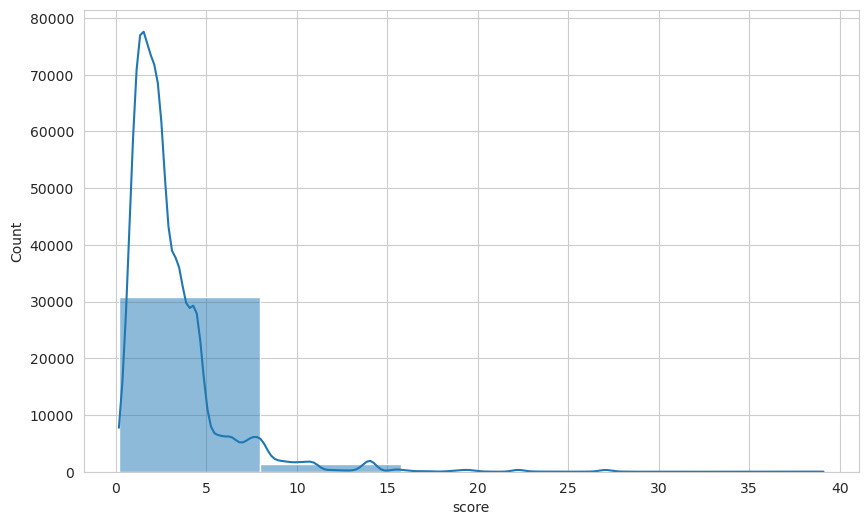

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(final_df['score'], kde=True, bins=5)

plt.show()

### specific

In [16]:
spe = pd.read_csv('./tf/tf_tf/specific_36085.csv', index_col=0)
spe

,motif_motif,tf_tf,cell_type,score
0,AHR_CREB/ATF/1,AHR_CREM,mast_cells,0.013182
1,AHR_CREB/ATF/1,ARNT_JUND,mast_cells,0.013182
2,AHR_CREB/ATF/1,ARNT_FOS,mast_cells,0.013182
3,AHR_CREB/ATF/1,ARNT_FOSL1,mast_cells,0.013182
4,AHR_CREB/ATF/1,ARNT_CREM,mast_cells,0.013182
...,...,...,...,...
59444,ZNF667_ZNF85,ZNF667_ZNF85,plasma_cells,0.031109
59445,ZNF680_ZSCAN4,ZNF680_ZSCAN4,cycling_cells,0.009475
59446,ZNF713_ZNF784,ZNF713_ZNF784,cycling_cells,0.005519
59447,ZNF713_ZSCAN3,ZNF713_ZSCAN31,cycling_cells,0.005554


In [17]:
spe_exp = pd.read_csv('./tf/tf_tf/tf_specific_expression.csv', index_col=0)
spe_exp

,b-cell_lineage,b_cells,cycling_cells,dc,early_mk,erythroid,hsc_mpp,ilc,macrophages,mast_cells,monocytes,pdc,plasma_cells,t_cells
gene_name,,,,,,,,,,,,,,
FOXH1,0.000000,0.077813,0.000000,0.133934,0.073597,0.320732,0.040693,0.077747,0.000000,0.095442,0.054402,0.079989,0.054633,0.079086
FOXI1,0.000000,0.021085,0.000000,0.017091,0.013165,0.006680,0.004895,0.012994,0.000000,0.000000,0.027793,0.019092,0.044243,0.024200
ATF1,1.523323,1.574805,1.581057,1.602209,1.739028,1.933144,1.569251,1.654590,1.601129,1.724474,1.567403,1.514922,1.486086,1.629556
HES5,0.000000,0.023365,0.000000,0.049378,0.208325,0.229821,0.068890,0.032342,0.143974,0.065899,0.015186,0.054928,0.022685,0.014106
ZNF136,1.523323,1.548801,1.335660,1.361262,1.378940,1.533573,1.390557,1.559960,1.472675,1.362455,1.386652,1.452499,1.170481,1.548778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NOTO,0.000000,0.018792,0.000000,0.008629,0.000000,0.009982,0.024715,0.017625,0.000000,0.017436,0.015186,0.019092,0.011490,0.014602
POU1F1,0.000000,0.019940,0.076020,0.000000,0.000000,0.016512,0.018470,0.023345,0.000000,0.017436,0.014653,0.009651,0.000000,0.024781
ETS1,2.053236,2.491085,2.784303,1.691657,1.395920,1.475750,1.625363,2.662546,1.988127,1.494591,1.535035,2.120434,2.129123,2.824176


In [18]:
spe_ratio = pd.read_csv('./tf/tf_tf/tf_specific_expression_ratio.csv', index_col=0)
spe_ratio

,b-cell_lineage,b_cells,cycling_cells,dc,early_mk,erythroid,hsc_mpp,ilc,macrophages,mast_cells,monocytes,pdc,plasma_cells,t_cells
gene_name,,,,,,,,,,,,,,
FOXH1,0.000000,1.001297,0.000000,1.824841,0.943117,5.433743,0.505076,1.000387,0.000000,1.249969,0.684190,1.031521,0.687255,1.018971
FOXI1,0.000000,1.610907,0.000000,1.275820,0.961117,0.470555,0.341467,0.947738,0.000000,0.000000,2.210625,1.441752,3.912751,1.883390
ATF1,0.935099,0.969057,0.973192,0.987201,1.078496,1.210086,0.965385,1.022013,0.986485,1.068727,0.964164,0.929573,0.910640,1.005354
HES5,0.000000,0.335438,0.000000,0.729845,3.758417,4.273728,1.041354,0.468955,2.384511,0.992685,0.216065,0.817032,0.325418,0.200465
ZNF136,1.070310,1.089713,0.929032,0.948139,0.961363,1.078110,0.970066,1.098227,1.031900,0.949031,0.967140,1.016657,0.807008,1.089695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NOTO,0.000000,1.760580,0.000000,0.753310,0.000000,0.879402,2.418775,1.637484,0.000000,1.617708,1.386747,1.792544,1.022697,1.327928
POU1F1,0.000000,1.290492,6.825621,0.000000,0.000000,1.050721,1.186716,1.536894,0.000000,1.114532,0.924013,0.594156,0.000000,1.643393
ETS1,1.018078,1.256159,1.420170,0.827381,0.675225,0.715967,0.792979,1.351610,0.983352,0.725617,0.746380,1.054099,1.058770,1.442765


In [19]:
import pandas as pd
import numpy as np

# --- 2. Core Processing Logic ---

# Step 1: Split the 'tf_tf' column in 'spe' into 'tf1' and 'tf2'
spe[['tf1', 'tf2']] = spe['tf_tf'].str.split('_', expand=True)

# Step 2: Define a function to process a single row and perform lookups
def get_exp_ratio(row):
    # Get tf1, tf2, and cell_type from the current row
    tf1 = row['tf1']
    tf2 = row['tf2']
    cell_type = row['cell_type']
    
    # Use try-except to handle potential lookup failures (e.g., if a specific tf or cell_type does not exist)
    try:
        exp1 = spe_exp.loc[tf1, cell_type]
    except KeyError:
        exp1 = np.nan # Fill with NaN if lookup fails
        
    try:
        exp2 = spe_exp.loc[tf2, cell_type]
    except KeyError:
        exp2 = np.nan
        
    try:
        ratio1 = spe_ratio.loc[tf1, cell_type]
    except KeyError:
        ratio1 = np.nan
        
    try:
        ratio2 = spe_ratio.loc[tf2, cell_type]
    except KeyError:
        ratio2 = np.nan
        
    # Return a Series containing four new values
    return pd.Series([exp1, exp2, ratio1, ratio2], index=['tf1_exp', 'tf2_exp', 'tf1_ratio', 'tf2_ratio'])

# Step 3: Apply this function to each row of the spe DataFrame (axis=1)
new_columns = spe.apply(get_exp_ratio, axis=1)

# Step 4: Concatenate the newly generated columns back to the original spe DataFrame
final_spe_df = pd.concat([spe, new_columns], axis=1)

In [20]:
final_spe_df

,motif_motif,tf_tf,cell_type,score,tf1,tf2,tf1_exp,tf2_exp,tf1_ratio,tf2_ratio
0,AHR_CREB/ATF/1,AHR_CREM,mast_cells,0.013182,AHR,CREM,1.870898,1.556099,0.885223,0.895527
1,AHR_CREB/ATF/1,ARNT_JUND,mast_cells,0.013182,ARNT,JUND,1.714290,2.148759,0.985616,0.971723
2,AHR_CREB/ATF/1,ARNT_FOS,mast_cells,0.013182,ARNT,FOS,1.714290,2.342328,0.985616,0.933483
3,AHR_CREB/ATF/1,ARNT_FOSL1,mast_cells,0.013182,ARNT,FOSL1,1.714290,1.316905,0.985616,1.141743
4,AHR_CREB/ATF/1,ARNT_CREM,mast_cells,0.013182,ARNT,CREM,1.714290,1.556099,0.985616,0.895527
...,...,...,...,...,...,...,...,...,...,...
59444,ZNF667_ZNF85,ZNF667_ZNF85,plasma_cells,0.031109,ZNF667,ZNF85,0.393502,0.999198,0.421577,0.849869
59445,ZNF680_ZSCAN4,ZNF680_ZSCAN4,cycling_cells,0.009475,ZNF680,ZSCAN4,1.525310,0.000000,1.013592,0.000000
59446,ZNF713_ZNF784,ZNF713_ZNF784,cycling_cells,0.005519,ZNF713,ZNF784,1.146382,0.246791,0.804668,0.440180
59447,ZNF713_ZSCAN3,ZNF713_ZSCAN31,cycling_cells,0.005554,ZNF713,ZSCAN31,1.146382,0.246791,0.804668,0.550995


In [41]:
condition = (
    (final_spe_df['score'] > 0.01) &
    (final_spe_df['tf1_exp'] > 0.5) &
    (final_spe_df['tf2_exp'] > 0.5) &
    (final_spe_df['tf1_ratio'] > 1) &
    (final_spe_df['tf2_ratio'] > 1)
)

filtered_spe_df = final_spe_df[condition]
filtered_spe_df

,motif_motif,tf_tf,cell_type,score,tf1,tf2,tf1_exp,tf2_exp,tf1_ratio,tf2_ratio
51,AHR_EBF1,AHR_EBF1,b-cell_lineage,0.033615,AHR,EBF1,2.141253,3.226498,1.023211,1.682020
143,AHR_HD/18,AHR_HOXA10,b-cell_lineage,0.028071,AHR,HOXA10,2.141253,1.228779,1.023211,1.805473
226,AHR_KAISO,AHR_ZBTB33,macrophages,0.030570,AHR,ZBTB33,2.706927,1.157291,1.320989,1.005461
227,AHR_KAISO,ARNT_ZBTB33,macrophages,0.030570,ARNT,ZBTB33,1.766330,1.157291,1.017879,1.005461
251,AHR_MEF2,AHR_MEF2D,b-cell_lineage,0.074874,AHR,MEF2D,2.141253,1.932744,1.023211,1.043751
...,...,...,...,...,...,...,...,...,...,...
59386,ZNF423_ZNF528,ZNF423_ZNF528,b-cell_lineage,0.057566,ZNF423,ZNF528,0.998403,0.998403,2.673602,1.059738
59397,ZNF431_ZNF784,ZNF431_ZNF784,b-cell_lineage,0.017117,ZNF431,ZNF784,2.023548,0.542801,1.060633,1.009132
59415,ZNF528_ZNF768,ZNF528_ZNF768,b-cell_lineage,0.140536,ZNF528,ZNF768,0.998403,0.952665,1.059738,1.295477
59425,ZNF554_ZNF784,ZNF554_ZNF784,b-cell_lineage,0.054391,ZNF554,ZNF784,0.776673,0.542801,1.277811,1.009132


In [22]:
filtered_spe_df['cell_type'].value_counts()   # monocyte

cell_type
b-cell_lineage    660
macrophages       535
dc                194
cycling_cells     126
mast_cells         90
pdc                78
early_mk           69
plasma_cells       36
erythroid          31
t_cells            26
ilc                24
b_cells             7
hsc_mpp             7
monocytes           5
Name: count, dtype: int64

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(final_spe_df['tf1_exp'], kde=True, bins=5)

plt.show()

## PPI visual

### common

In [8]:
# filtered_df.to_csv('./tf/tf_tf/common_filtered_339.csv')
filtered_df = pd.read_csv('./tf/tf_tf/common_filtered_339.csv', index_col=0)
filtered_df

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
1597,ATF1_ATF7,ATF1,ATF7,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,25.669878,14
1599,ATF1_CREB3,ATF1,CREB3,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,12.737690,14
1600,ATF1_CREB5,ATF1,CREB5,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,19.327195,14
1605,ATF1_JDP2,ATF1,JDP2,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,14.033428,14
1606,ATF1_MAFB,ATF1,MAFB,10.277222,CREB/ATF/1_CREB/ATF/2,22.700978,14,11.760669,14
...,...,...,...,...,...,...,...,...,...
32134,ZBTB17_ZNF770,ZBTB17,ZNF770,14.069301,GC-tract_KLF/SP/2,19.660017,14,20.516318,14
32137,ZBTB18_ZEB1,ZBTB18,ZEB1,10.912522,Ebox/CACCTG_Ebox/CAGCTG,18.160063,14,33.031295,14
32269,ZNF263_ZNF281,ZNF263,ZNF281,14.069301,GC-tract_KLF/SP/2,18.387812,14,19.246573,14
32282,ZNF281_ZNF341,ZNF281,ZNF341,14.069301,GC-tract_KLF/SP/2,19.246573,14,13.358270,14


In [16]:
# Get the unique TFs from 'tf1' and 'tf2' columns
unique_tfs = pd.unique(filtered_df[['tf1', 'tf2']].values.ravel('K'))

# Count the number of unique TFs
num_unique_tfs = len(unique_tfs)
num_unique_tfs

116

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Set font and PDF output parameters
plt.rcParams['pdf.fonttype'] = 42      # Ensure text is embedded as TrueType fonts
plt.rcParams['ps.fonttype'] = 42       # If PostScript output is required

# Construct the graph
G = nx.from_pandas_edgelist(filtered_df, "tf1", "tf2", edge_attr="score")

# Calculate node centrality
centrality = nx.degree_centrality(G)

# Normalize node sizes (reduce range to avoid overlap)
node_sizes = np.interp(
    list(centrality.values()),
    (min(centrality.values()), max(centrality.values())),
    (100, 800)
)

# Edge color mapping
scores = [d['score'] for (_, _, d) in G.edges(data=True)]
norm = plt.Normalize(vmin=min(scores), vmax=max(scores))
edge_colors = cm.plasma(norm(scores))

# Improve layout: increase k value or use kamada_kawai
pos = nx.spring_layout(G, k=2.0, seed=42)
# pos = nx.kamada_kawai_layout(G)  # Alternative layout option

fig, ax = plt.subplots(figsize=(12, 10))

# Draw nodes
nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color="skyblue",
    alpha=0.9,
    edgecolors="black",
    ax=ax
)

# Draw edges
nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    width=np.interp(scores, (min(scores), max(scores)), (0.5, 2)),
    alpha=0.3,
    ax=ax
)

# Labels (Show top 50, add offset to avoid overlapping nodes)
top_nodes = sorted(centrality, key=centrality.get, reverse=True)[:50]
for n in top_nodes:
    x, y = pos[n]
    ax.text(
        x, y+0.05,  # Shift upwards
        n,
        fontsize=9,
        ha="center", va="center",
        bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1)  # White background to prevent overlap with edges
    )

# Add colorbar
sm = plt.cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Edge Score")

ax.set_title("Improved PPI Network (Reduced Overlap)", fontsize=14)
ax.axis("off")
plt.savefig("ppi_network.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Construct the graph
G = nx.from_pandas_edgelist(filtered_df, "tf1", "tf2", edge_attr="score")

# Calculate node centrality
centrality = nx.degree_centrality(G)

# Normalize node sizes
min_centrality = min(centrality.values())
max_centrality = max(centrality.values())
node_sizes = np.interp(
    list(centrality.values()),
    (min_centrality, max_centrality),
    (100, 800)
)

# Edge color mapping
scores = [d['score'] for (_, _, d) in G.edges(data=True)]
norm = plt.Normalize(vmin=min(scores), vmax=max(scores))
edge_colors = cm.plasma(norm(scores))

# Layout
pos = nx.spring_layout(G, k=2.0, seed=42)

fig, ax = plt.subplots(figsize=(14, 12))

# Draw nodes
nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color="skyblue",
    alpha=0.9,
    edgecolors="black",
    ax=ax
)

# Draw edges
nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    width=np.interp(scores, (min(scores), max(scores)), (0.5, 2)),
    alpha=0.3,
    ax=ax
)

# Labels (Show top 20 only, with slight offset)
top_nodes = sorted(centrality, key=centrality.get, reverse=True)[:20]
for n in top_nodes:
    x, y = pos[n]
    ax.text(
        x, y+0.05, n,
        fontsize=9,
        ha="center", va="center",
        bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1)
    )

# Add colorbar
sm = plt.cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.8)
cbar.set_label("Edge Score", fontsize=12)

# ==================== Code for adding node size legend ====================
# Create proxy artists for the legend
legend_handles = []
legend_labels = []
# Define representative centrality values to display in the legend
centrality_levels = np.linspace(min_centrality, max_centrality, num=4)
# Calculate node sizes corresponding to these centrality values
size_levels = np.interp(centrality_levels, (min_centrality, max_centrality), (100, 800))

for i, size in enumerate(size_levels):
    legend_handles.append(plt.scatter([], [], s=size, color='skyblue', edgecolor='black', alpha=0.9))
    legend_labels.append(f'{centrality_levels[i]:.2f}')

legend = ax.legend(legend_handles, legend_labels, title='Node Centrality', scatterpoints=1, labelspacing=1.5, frameon=True, loc='lower right')
legend.get_title().set_fontsize('12')
# =================================================================

ax.set_title("Improved PPI Network (Reduced Overlap)", fontsize=16)
ax.axis("off")

# Save as PDF (vector graphic, suitable for papers) and PNG
plt.savefig("ppi_network_with_legend.pdf", format="pdf", bbox_inches="tight")
plt.savefig("ppi_network_with_legend.png", format="png", bbox_inches="tight", dpi=300)

plt.show()

### spe

In [49]:
# filtered_spe_df.to_csv('./tf/tf_tf/specific_filtered_1888.csv')
filtered_spe_df = pd.read_csv('./tf/tf_tf/specific_filtered_1888.csv', index_col=0)
filtered_spe_df

,motif_motif,tf_tf,cell_type,score,tf1,tf2,tf1_exp,tf2_exp,tf1_ratio,tf2_ratio
51,AHR_EBF1,AHR_EBF1,b-cell_lineage,0.033615,AHR,EBF1,2.141253,3.226498,1.023211,1.682020
143,AHR_HD/18,AHR_HOXA10,b-cell_lineage,0.028071,AHR,HOXA10,2.141253,1.228779,1.023211,1.805473
226,AHR_KAISO,AHR_ZBTB33,macrophages,0.030570,AHR,ZBTB33,2.706927,1.157291,1.320989,1.005461
227,AHR_KAISO,ARNT_ZBTB33,macrophages,0.030570,ARNT,ZBTB33,1.766330,1.157291,1.017879,1.005461
251,AHR_MEF2,AHR_MEF2D,b-cell_lineage,0.074874,AHR,MEF2D,2.141253,1.932744,1.023211,1.043751
...,...,...,...,...,...,...,...,...,...,...
59386,ZNF423_ZNF528,ZNF423_ZNF528,b-cell_lineage,0.057566,ZNF423,ZNF528,0.998403,0.998403,2.673602,1.059738
59397,ZNF431_ZNF784,ZNF431_ZNF784,b-cell_lineage,0.017117,ZNF431,ZNF784,2.023548,0.542801,1.060633,1.009132
59415,ZNF528_ZNF768,ZNF528_ZNF768,b-cell_lineage,0.140536,ZNF528,ZNF768,0.998403,0.952665,1.059738,1.295477
59425,ZNF554_ZNF784,ZNF554_ZNF784,b-cell_lineage,0.054391,ZNF554,ZNF784,0.776673,0.542801,1.277811,1.009132


In [50]:
filtered_spe_df['cell_type'].value_counts()

cell_type
b-cell_lineage    660
macrophages       535
dc                194
cycling_cells     126
mast_cells         90
pdc                78
early_mk           69
plasma_cells       36
erythroid          31
t_cells            26
ilc                24
b_cells             7
hsc_mpp             7
monocytes           5
Name: count, dtype: int64

In [51]:
filtered_spe_df = filtered_spe_df[filtered_spe_df['cell_type'] == 'dc']
filtered_spe_df

,motif_motif,tf_tf,cell_type,score,tf1,tf2,tf1_exp,tf2_exp,tf1_ratio,tf2_ratio
309,AHR_NR/15,AHR_VDR,dc,0.090896,AHR,VDR,2.665076,1.735143,1.298526,1.759904
384,AHR_TFCP2,AHR_TFCP2,dc,0.083525,AHR,TFCP2,2.665076,2.098876,1.298526,1.055352
696,AP1/1_E2F/1,BATF_E2F4,dc,0.224450,BATF,E2F4,1.194521,1.354379,1.000991,1.058086
714,AP1/1_E2F/1,E2F4_NFE2L1,dc,0.224450,E2F4,NFE2L1,1.354379,1.460228,1.058086,1.006635
920,AP1/1_HD/18,ARID3A_FOS,dc,0.115811,ARID3A,FOS,1.769215,3.017051,1.044105,1.227774
...,...,...,...,...,...,...,...,...,...,...
52077,NR/19_PRDM1,NR1D2_PRDM1,dc,0.015909,NR1D2,PRDM1,1.829484,1.412379,1.010006,1.171919
55318,RFX/2_RUNX/1,RFX2_RUNX3,dc,0.066718,RFX2,RUNX3,1.897447,2.102745,1.014159,1.107869
55319,RFX/2_RUNX/1,RFX2_RUNX2,dc,0.066718,RFX2,RUNX2,1.897447,2.524166,1.014159,1.159220
58323,SRF_ZBTB48,SRF_ZBTB48,dc,0.024443,SRF,ZBTB48,1.224639,1.344635,1.138671,1.140968


In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Construct the graph
G = nx.from_pandas_edgelist(filtered_spe_df, "tf1", "tf2", edge_attr="score")

# Calculate node centrality
centrality = nx.degree_centrality(G)

# Normalize node sizes
min_centrality = min(centrality.values())
max_centrality = max(centrality.values())
node_sizes = np.interp(
    list(centrality.values()),
    (min_centrality, max_centrality),
    (100, 800)
)

# Edge color mapping
scores = [d['score'] for (_, _, d) in G.edges(data=True)]
norm = plt.Normalize(vmin=min(scores), vmax=max(scores))
edge_colors = cm.plasma(norm(scores))

# Layout configuration
pos = nx.spring_layout(G, k=2.0, seed=42)

fig, ax = plt.subplots(figsize=(14, 12))

# Draw nodes
nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color="skyblue",
    alpha=0.9,
    edgecolors="black",
    ax=ax
)

# Draw edges
nx.draw_networkx_edges(
    G, pos,
    edge_color=edge_colors,
    width=np.interp(scores, (min(scores), max(scores)), (0.5, 2)),
    alpha=0.3,
    ax=ax
)

# Labels (Show top 20 only, with slight offset)
top_nodes = sorted(centrality, key=centrality.get, reverse=True)[:20]
for n in top_nodes:
    x, y = pos[n]
    ax.text(
        x, y+0.05, n,
        fontsize=9,
        ha="center", va="center",
        bbox=dict(facecolor="white", alpha=0.6, edgecolor="none", pad=1)
    )

# Add colorbar
sm = plt.cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.8)
cbar.set_label("Edge Score", fontsize=12)

# ==================== Code for adding node size legend ====================
# Create proxy artists for the legend
legend_handles = []
legend_labels = []
# Define representative centrality values to display in the legend
centrality_levels = np.linspace(min_centrality, max_centrality, num=4)
# Calculate node sizes corresponding to these centrality values
size_levels = np.interp(centrality_levels, (min_centrality, max_centrality), (100, 800))

for i, size in enumerate(size_levels):
    legend_handles.append(plt.scatter([], [], s=size, color='skyblue', edgecolor='black', alpha=0.9))
    legend_labels.append(f'{centrality_levels[i]:.2f}')

legend = ax.legend(legend_handles, legend_labels, title='Node Centrality', scatterpoints=1, labelspacing=1.5, frameon=True, loc='lower right')
legend.get_title().set_fontsize('12')
# =================================================================

ax.set_title("Improved PPI Network (Reduced Overlap)", fontsize=16)
ax.axis("off")

# Save as PDF (vector graphic, suitable for papers) and PNG
plt.savefig("ppi_network_with_legend.pdf", format="pdf", bbox_inches="tight")
plt.savefig("ppi_network_with_legend.png", format="png", bbox_inches="tight", dpi=300)

plt.show()

## common validate alternatives

In [3]:
com = pd.read_csv('./tf/tf_tf/common_32374.csv', index_col=0)
com

,tf_tf,score,motif_motif
0,AHR_ARNT,1.924693,AHR_HIF
1,AHR_ASCL1,1.324000,AHR_Ebox/CAGCTG
2,AHR_ASCL2,1.324000,AHR_Ebox/CAGCTG
3,AHR_CTCF,0.565092,AHR_CTCF
4,AHR_CTCFL,0.565092,AHR_CTCF
...,...,...,...
37325,ZNF740_ZSCAN22,3.029397,GC-tract_ZIC/2
37326,ZNF768_ZNF770,3.802317,GC-tract_ZNF768
37327,ZNF768_ZSCAN22,3.802317,GC-tract_ZNF768
37328,ZNF816_ZNF827,4.693605,MZF1_ZNF354


In [4]:
com_exp = pd.read_csv('tf/tf_tf/tf_common_expression.csv')
com_exp

,gene_name,sum,non_zero
0,FOXH1,1.088069,11
1,FOXI1,0.191238,10
2,ATF1,22.700978,14
3,HES5,0.928900,12
4,ZNF136,20.025615,14
...,...,...,...
680,NOTO,0.157550,10
681,POU1F1,0.220807,9
682,ETS1,28.271345,14
683,VDR,14.552236,14


In [23]:
com_exp[com_exp['gene_name'] == 'RORB']

,gene_name,sum,non_zero
462,RORB,5.783552,14


In [5]:
import pandas as pd

# Step 1: Split the 'tf_tf' column in 'com' into 'tf1' and 'tf2'
com[['tf1', 'tf2']] = com['tf_tf'].str.split('_', expand=True)

# Step 2: First merge to populate information for 'tf1'
# Left merge 'com' and 'com_exp', matching com['tf1'] with com_exp['gene_name']
# The suffixes parameter distinguishes columns with the same name from both DataFrames (though not strictly needed here, it's good practice)
merged_df = pd.merge(
    com,
    com_exp,
    left_on='tf1',
    right_on='gene_name',
    how='left'
)

# Rename the columns populated after the first merge for distinction
merged_df = merged_df.rename(columns={'sum': 'tf1_sum', 'non_zero': 'tf1_non_zero'})
# Drop the redundant 'gene_name' column
merged_df = merged_df.drop(columns='gene_name')


# Step 3: Second merge to populate information for 'tf2'
# Perform another left merge on the result of the previous step, this time matching com['tf2'] with com_exp['gene_name']
final_df = pd.merge(
    merged_df,
    com_exp,
    left_on='tf2',
    right_on='gene_name',
    how='left'
)

# Rename the columns populated after the second merge
final_df = final_df.rename(columns={'sum': 'tf2_sum', 'non_zero': 'tf2_non_zero'})
# Drop the redundant 'gene_name' column again
final_df = final_df.drop(columns='gene_name')


# --- 3. Print Results ---

print("Original 'com' DataFrame:")
print(com.head())
print("\nOriginal 'com_exp' DataFrame:")
print(com_exp.head())
print("\n" + "="*50)
print("Final result populated with sum and non_zero information:")
# Reorder columns for better presentation
final_df = final_df[['tf_tf', 'tf1', 'tf2', 'score', 'motif_motif', 'tf1_sum', 'tf1_non_zero', 'tf2_sum', 'tf2_non_zero']]
print(final_df)

原始的 'com' DataFrame:
       tf_tf     score      motif_motif  tf1    tf2
0   AHR_ARNT  1.924693          AHR_HIF  AHR   ARNT
1  AHR_ASCL1  1.324000  AHR_Ebox/CAGCTG  AHR  ASCL1
2  AHR_ASCL2  1.324000  AHR_Ebox/CAGCTG  AHR  ASCL2
3   AHR_CTCF  0.565092         AHR_CTCF  AHR   CTCF
4  AHR_CTCFL  0.565092         AHR_CTCF  AHR  CTCFL

原始的 'com_exp' DataFrame:
  gene_name        sum  non_zero
0     FOXH1   1.088069        11
1     FOXI1   0.191238        10
2      ATF1  22.700978        14
3      HES5   0.928900        12
4    ZNF136  20.025615        14

最终填充了sum和non_zero信息的结果:
                 tf_tf      tf1      tf2     score      motif_motif  \
0             AHR_ARNT      AHR     ARNT  1.924693          AHR_HIF   
1            AHR_ASCL1      AHR    ASCL1  1.324000  AHR_Ebox/CAGCTG   
2            AHR_ASCL2      AHR    ASCL2  1.324000  AHR_Ebox/CAGCTG   
3             AHR_CTCF      AHR     CTCF  0.565092         AHR_CTCF   
4            AHR_CTCFL      AHR    CTCFL  0.565092         AHR_

In [8]:
final_df

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
0,AHR_ARNT,AHR,ARNT,1.924693,AHR_HIF,29.346097,14,24.325287,14
1,AHR_ASCL1,AHR,ASCL1,1.324000,AHR_Ebox/CAGCTG,29.346097,14,0.046758,7
2,AHR_ASCL2,AHR,ASCL2,1.324000,AHR_Ebox/CAGCTG,29.346097,14,8.594867,14
3,AHR_CTCF,AHR,CTCF,0.565092,AHR_CTCF,29.346097,14,29.130219,14
4,AHR_CTCFL,AHR,CTCFL,0.565092,AHR_CTCF,29.346097,14,0.772454,13
...,...,...,...,...,...,...,...,...,...
32369,ZNF740_ZSCAN22,ZNF740,ZSCAN22,3.029397,GC-tract_ZIC/2,15.331960,14,5.026648,14
32370,ZNF768_ZNF770,ZNF768,ZNF770,3.802317,GC-tract_ZNF768,10.512581,14,20.516318,14
32371,ZNF768_ZSCAN22,ZNF768,ZSCAN22,3.802317,GC-tract_ZNF768,10.512581,14,5.026648,14
32372,ZNF816_ZNF827,ZNF816,ZNF827,4.693605,MZF1_ZNF354,8.537254,14,25.912860,14


In [11]:
r1 = final_df[final_df['tf1'] == 'RUNX1']
r1

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
29391,RUNX1_RXRG,RUNX1,RXRG,2.385172,NR/12_RUNX/1,41.298522,14,0.202015,9
29392,RUNX1_SMAD3,RUNX1,SMAD3,1.953141,RUNX/1_SMAD,41.298522,14,29.756026,14
29393,RUNX1_SMAD4,RUNX1,SMAD4,1.953141,RUNX/1_SMAD,41.298522,14,28.065819,14
29394,RUNX1_SP1,RUNX1,SP1,1.751400,KLF/SP/1_RUNX/1,41.298522,14,22.475984,14
29395,RUNX1_SP3,RUNX1,SP3,1.751400,KLF/SP/1_RUNX/1,41.298522,14,33.464828,14
29396,RUNX1_SP4,RUNX1,SP4,1.751400,KLF/SP/1_RUNX/1,41.298522,14,25.039922,14
29397,RUNX1_SP8,RUNX1,SP8,1.751400,KLF/SP/1_RUNX/1,41.298522,14,0.077488,9
29398,RUNX1_SREBF1,RUNX1,SREBF1,4.494045,"Ebox/CACGTG/1_RUNX/1, RUNX/1_SREBF1",41.298522,14,20.588397,14
29399,RUNX1_SREBF2,RUNX1,SREBF2,4.494045,"Ebox/CACGTG/1_RUNX/1, RUNX/1_SREBF1",41.298522,14,29.980930,14
29400,RUNX1_TBX20,RUNX1,TBX20,1.953141,RUNX/1_SMAD,41.298522,14,0.755388,11


In [12]:
r2 = final_df[final_df['tf2'] == 'RUNX1']
r2

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
956,ARNTL_RUNX1,ARNTL,RUNX1,2.733813,Ebox/CACGTG/1_RUNX/1,22.705426,14,41.298522,14
1437,AR_RUNX1,AR,RUNX1,2.725292,FOX/4_RUNX/1,6.201082,13,41.298522,14
2773,BHLHE40_RUNX1,BHLHE40,RUNX1,2.733813,Ebox/CACGTG/1_RUNX/1,19.565736,14,41.298522,14
2906,BHLHE41_RUNX1,BHLHE41,RUNX1,2.733813,Ebox/CACGTG/1_RUNX/1,4.116882,13,41.298522,14
3528,CLOCK_RUNX1,CLOCK,RUNX1,2.733813,Ebox/CACGTG/1_RUNX/1,25.450453,14,41.298522,14
...,...,...,...,...,...,...,...,...,...
28818,RELB_RUNX1,RELB,RUNX1,5.397689,NFKB/1_RUNX/1,24.592628,14,41.298522,14
28873,REL_RUNX1,REL,RUNX1,5.397689,NFKB/1_RUNX/1,31.541432,14,41.298522,14
29166,RORA_RUNX1,RORA,RUNX1,5.010838,"NR/12_RUNX/1, NR/19_RUNX/1",29.830390,14,41.298522,14
29268,RORB_RUNX1,RORB,RUNX1,2.625666,NR/19_RUNX/1,5.783552,14,41.298522,14


In [14]:
ru = pd.concat([r1, r2])
ru

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
29391,RUNX1_RXRG,RUNX1,RXRG,2.385172,NR/12_RUNX/1,41.298522,14,0.202015,9
29392,RUNX1_SMAD3,RUNX1,SMAD3,1.953141,RUNX/1_SMAD,41.298522,14,29.756026,14
29393,RUNX1_SMAD4,RUNX1,SMAD4,1.953141,RUNX/1_SMAD,41.298522,14,28.065819,14
29394,RUNX1_SP1,RUNX1,SP1,1.751400,KLF/SP/1_RUNX/1,41.298522,14,22.475984,14
29395,RUNX1_SP3,RUNX1,SP3,1.751400,KLF/SP/1_RUNX/1,41.298522,14,33.464828,14
...,...,...,...,...,...,...,...,...,...
28818,RELB_RUNX1,RELB,RUNX1,5.397689,NFKB/1_RUNX/1,24.592628,14,41.298522,14
28873,REL_RUNX1,REL,RUNX1,5.397689,NFKB/1_RUNX/1,31.541432,14,41.298522,14
29166,RORA_RUNX1,RORA,RUNX1,5.010838,"NR/12_RUNX/1, NR/19_RUNX/1",29.830390,14,41.298522,14
29268,RORB_RUNX1,RORB,RUNX1,2.625666,NR/19_RUNX/1,5.783552,14,41.298522,14


In [19]:
condition = (
    (ru['score'] > 5) &
    (ru['tf1_sum'] > 8) &
    (ru['tf1_non_zero'] > 13) &
    (ru['tf2_sum'] > 8) &
    (ru['tf2_non_zero'] > 13)
)

filtered_df = ru[condition]
filtered_df

,tf_tf,tf1,tf2,score,motif_motif,tf1_sum,tf1_non_zero,tf2_sum,tf2_non_zero
24324,NFKB1_RUNX1,NFKB1,RUNX1,5.397689,NFKB/1_RUNX/1,35.275966,14,41.298522,14
24356,NFKB2_RUNX1,NFKB2,RUNX1,5.397689,NFKB/1_RUNX/1,18.287895,14,41.298522,14
28791,RELA_RUNX1,RELA,RUNX1,5.397689,NFKB/1_RUNX/1,17.964891,14,41.298522,14
28818,RELB_RUNX1,RELB,RUNX1,5.397689,NFKB/1_RUNX/1,24.592628,14,41.298522,14
28873,REL_RUNX1,REL,RUNX1,5.397689,NFKB/1_RUNX/1,31.541432,14,41.298522,14
29166,RORA_RUNX1,RORA,RUNX1,5.010838,"NR/12_RUNX/1, NR/19_RUNX/1",29.830390,14,41.298522,14


## spe validate alternatives

In [20]:
spe = pd.read_csv('./tf/tf_tf/specific_filtered_1888.csv', index_col=0)
spe

,motif_motif,tf_tf,cell_type,score,tf1,tf2,tf1_exp,tf2_exp,tf1_ratio,tf2_ratio
51,AHR_EBF1,AHR_EBF1,b-cell_lineage,0.033615,AHR,EBF1,2.141253,3.226498,1.023211,1.682020
143,AHR_HD/18,AHR_HOXA10,b-cell_lineage,0.028071,AHR,HOXA10,2.141253,1.228779,1.023211,1.805473
226,AHR_KAISO,AHR_ZBTB33,macrophages,0.030570,AHR,ZBTB33,2.706927,1.157291,1.320989,1.005461
227,AHR_KAISO,ARNT_ZBTB33,macrophages,0.030570,ARNT,ZBTB33,1.766330,1.157291,1.017879,1.005461
251,AHR_MEF2,AHR_MEF2D,b-cell_lineage,0.074874,AHR,MEF2D,2.141253,1.932744,1.023211,1.043751
...,...,...,...,...,...,...,...,...,...,...
59386,ZNF423_ZNF528,ZNF423_ZNF528,b-cell_lineage,0.057566,ZNF423,ZNF528,0.998403,0.998403,2.673602,1.059738
59397,ZNF431_ZNF784,ZNF431_ZNF784,b-cell_lineage,0.017117,ZNF431,ZNF784,2.023548,0.542801,1.060633,1.009132
59415,ZNF528_ZNF768,ZNF528_ZNF768,b-cell_lineage,0.140536,ZNF528,ZNF768,0.998403,0.952665,1.059738,1.295477
59425,ZNF554_ZNF784,ZNF554_ZNF784,b-cell_lineage,0.054391,ZNF554,ZNF784,0.776673,0.542801,1.277811,1.009132


In [21]:
s1 = spe[spe['tf1'] == 'RUNX1']
s1

,motif_motif,tf_tf,cell_type,score,tf1,tf2,tf1_exp,tf2_exp,tf1_ratio,tf2_ratio
51194,NR/15_RUNX/1,RUNX1_VDR,macrophages,0.058917,RUNX1,VDR,3.033419,1.972043,1.030559,2.037851
55582,RUNX/1_ZFN121,RUNX1_ZNF121,b-cell_lineage,0.100062,RUNX1,ZNF121,3.061748,1.757924,1.040954,1.086045
55595,RUNX/1_ZNF282,RUNX1_ZNF282,b-cell_lineage,0.022109,RUNX1,ZNF282,3.061748,1.310066,1.040954,1.090768
55596,RUNX/1_ZNF335,RUNX1_ZNF335,pdc,0.026110,RUNX1,ZNF335,2.989975,1.528137,1.014648,1.000657


In [22]:
s2 = spe[spe['tf2'] == 'RUNX1']
s2

,motif_motif,tf_tf,cell_type,score,tf1,tf2,tf1_exp,tf2_exp,tf1_ratio,tf2_ratio
17573,EVI1/MECOM_RUNX/1,MECOM_RUNX1,b-cell_lineage,0.063599,MECOM,RUNX1,1.959666,3.061748,1.367666,1.040954
38916,HD/25_RUNX/1,HMBOX1_RUNX1,b-cell_lineage,0.055487,HMBOX1,RUNX1,2.260686,3.061748,1.025765,1.040954
44370,HIF_RUNX/1,HIF1A_RUNX1,b-cell_lineage,0.060937,HIF1A,RUNX1,2.508775,3.061748,1.023058,1.040954
49003,NFAT/1_RUNX/1,NFATC1_RUNX1,macrophages,0.021772,NFATC1,RUNX1,1.769243,3.033419,1.070407,1.030559
49816,NFI/2_RUNX/1,NFIC_RUNX1,b-cell_lineage,0.021169,NFIC,RUNX1,1.722534,3.061748,1.068785,1.040954
49817,NFI/2_RUNX/1,NFIA_RUNX1,b-cell_lineage,0.021169,NFIA,RUNX1,2.672171,3.061748,1.226046,1.040954
55560,RUNX/1_TBX/2,MGA_RUNX1,early_mk,0.030140,MGA,RUNX1,2.181663,3.433716,1.077896,1.178886
